# CS771 Mini-Project 1 — Parts 1–5: Next-day PM2.5 forecasting and mapping (Bihar)

This notebook runs top to bottom. Part 0 (Kanpur cleaning) is in its own notebook.

| Part | What this notebook does |
|---|---|
| 1 | Persistence and the fixed 29-feature Ridge baseline (the standalone Part 1 notebook, with a `lead_h` option on the feature builder) |
| 2 | Richer leakage-safe features, model comparison (ridge vs trees), forward group selection, an ablation table, and the improved model (0.5 Ridge + 0.5 Extra-trees on the change from today's reading) |
| 3 | Lead-time study (1, 3, 6, 12, 24 h) for persistence, the Part 1 ridge and the improved Part 2 model |
| 4 | IDW (p = 2) maps on the 0.05° grid: observed vs forecast vs persistence, map RMSE and pattern correlation |
| 5 | Refit the improved Part 2 model on all targets up to 30 Nov, write `submission/forecast.py` + `model.pkl`, run the official checker |

**Protocol (all parts).** Issue time = 12:00 IST on day *d*; target = 12:00 on *d+1*. Train = targets 1 Jan–31 Aug, validation = targets 1 Sep–30 Nov (all 468 stations, all 91 days). Every feature uses only rows at or before the issue time; anything fitted (regression weights, station climatology) is fitted on training rows only. Random seeds are fixed.

In [1]:
import os, sys, json, subprocess, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, ExtraTreesRegressor
import joblib

SEED = 0
np.random.seed(SEED)
pd.set_option('display.precision', 3)
warnings.filterwarnings('ignore', category=FutureWarning)

CANDIDATES = [Path('/content'), Path('/content/data'), Path('data'), Path('.')]
DATA_DIR = next((p for p in CANDIDATES if (p / 'bihar_pm25_hourly_jan_nov_2024.csv').exists()), None)
assert DATA_DIR is not None, 'Put the Bihar CSVs in /content, /content/data, ./data or the notebook folder.'
OUT_DIR = Path('outputs'); FIG_DIR = OUT_DIR / 'figures'; SUB_DIR = Path('submission')
for p in (OUT_DIR, FIG_DIR, SUB_DIR):
    p.mkdir(parents=True, exist_ok=True)
print('Data folder:', DATA_DIR.resolve())

Data folder: /content


In [2]:
W = pd.read_csv(DATA_DIR / 'bihar_pm25_hourly_jan_nov_2024.csv', index_col='timestamp', parse_dates=True)
W.columns = W.columns.astype(str)
stations = pd.read_csv(DATA_DIR / 'bihar_stations.csv', dtype={'sensor_id': str}).set_index('sensor_id')
grid = pd.read_csv(DATA_DIR / 'bihar_grid_005deg.csv')
boundary = pd.read_csv(DATA_DIR / 'bihar_boundary.csv')

assert W.index.is_monotonic_increasing and W.index.is_unique
assert list(stations.index) == list(W.columns)
assert (W.index[1:] - W.index[:-1] == pd.Timedelta(hours=1)).all(), 'hourly grid must be complete'
V = W.to_numpy(float)
T, N = V.shape
pos = {t: i for i, t in enumerate(W.index)}
print('Hourly table', V.shape, '| stations', N, '| grid points', len(grid), '| missing', int(np.isnan(V).sum()))

Hourly table (8040, 468) | stations 468 | grid points 3396 | missing 0


### Shared feature module

The feature code lives in one file, `submission/pm25_features.py`, which is written here and imported both by this notebook and by the submitted `forecast.py`. That guarantees the features used for validation are exactly the ones used by the submitted model. Each function only indexes rows `<= issue_row`; trailing window means are taken from cumulative sums.

In [3]:
%%writefile submission/pm25_features.py
import numpy as np
import pandas as pd

KM_X, KM_Y = 100.3, 110.6
RADII_KM = (15, 30, 60)

GROUP_FEATURES = {
    "lags24":       [f"lag{k}h" for k in range(24)],
    "history_days": [f"sameHour_d-{d}" for d in range(1, 7)] + ["mean_72h", "mean_168h", "std_168h", "min_168h"],
    "neigh_knn":    ["knn10_now", "knn10_24h", "knn10_168h"],
    "neigh_radius": [f"r{r}_{w}" for r in RADII_KM for w in ("now", "24h")],
    "network":      ["net_now", "net_6h", "net_24h", "net_168h"],
    "trend":        ["d_sameHour", "d_24hmean", "d_net24h"],
    "seasonal":     ["clim_train", "mean_30d", "rel_30d", "sin_doy", "cos_doy"],
    "dow":          ["sin_dow", "cos_dow"],
}
ALL_GROUPS = list(GROUP_FEATURES)
MAX_HISTORY_H = 168


def station_xy(lat, lon):
    return np.column_stack([(np.asarray(lon, float) - 85.5) * KM_X, (np.asarray(lat, float) - 25.7) * KM_Y])


def neighbour_matrices(xy, k=10, radii=RADII_KM):
    D = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    N = len(xy)
    order = np.argsort(D, axis=1, kind="stable")
    M = {}
    A = np.zeros((N, N)); A[np.arange(N)[:, None], order[:, :k]] = 1.0 / k
    M["knn10"] = A
    for r in radii:
        A = (D <= r).astype(float)
        empty = np.where(A.sum(1) == 0)[0]
        if len(empty):
            A[empty[:, None], order[empty, :3]] = 1.0
        M[f"r{r}"] = A / A.sum(1, keepdims=True)
    return M


def _win_mean(C, idx, w):
    lo = np.maximum(idx - w + 1, 0)
    return (C[idx + 1] - C[lo]) / (idx + 1 - lo)[:, None] if C.ndim == 2 else (C[idx + 1] - C[lo]) / (idx + 1 - lo)


def build_features(V, issue_idx, issue_times, groups, M, clim=None):
    issue_idx = np.asarray(issue_idx); n_i, N = len(issue_idx), V.shape[1]
    C = np.vstack([np.zeros((1, N)), np.cumsum(V, 0)])
    net = V.mean(1); Cn = np.concatenate([[0.0], np.cumsum(net)])
    cols = []
    full = lambda a: np.repeat(np.asarray(a)[:, None], N, 1)

    for g in groups:
        if g == "lags24":
            cols += [V[issue_idx - k] for k in range(24)]
        elif g == "history_days":
            cols += [V[issue_idx - 24 * d] for d in range(1, 7)]
            cols += [_win_mean(C, issue_idx, 72), _win_mean(C, issue_idx, 168)]
            win = np.stack([V[i - 167:i + 1] for i in issue_idx])
            cols += [win.std(1), win.min(1)]
        elif g == "neigh_knn":
            A = M["knn10"]
            cols += [V[issue_idx] @ A.T, _win_mean(C, issue_idx, 24) @ A.T, _win_mean(C, issue_idx, 168) @ A.T]
        elif g == "neigh_radius":
            m24 = _win_mean(C, issue_idx, 24)
            for r in RADII_KM:
                A = M[f"r{r}"]
                cols += [V[issue_idx] @ A.T, m24 @ A.T]
        elif g == "network":
            cols += [full(net[issue_idx]), full(_win_mean(Cn, issue_idx, 6)),
                     full(_win_mean(Cn, issue_idx, 24)), full(_win_mean(Cn, issue_idx, 168))]
        elif g == "trend":
            cols += [V[issue_idx] - V[issue_idx - 24],
                     _win_mean(C, issue_idx, 24) - _win_mean(C, issue_idx - 24, 24),
                     full(_win_mean(Cn, issue_idx, 24) - _win_mean(Cn, issue_idx - 24, 24))]
        elif g == "seasonal":
            m30 = _win_mean(C, issue_idx, 720); n30 = _win_mean(Cn, issue_idx, 720)
            cols += [np.repeat(np.asarray(clim)[None, :], n_i, 0), m30, m30 / np.maximum(n30[:, None], 1.0)]
            day = np.array([(pd.Timestamp(t).normalize() - pd.Timestamp("2024-01-01")).days for t in issue_times])
            ang = 2 * np.pi * day / 365.0
            cols += [full(np.sin(ang)), full(np.cos(ang))]
        elif g == "dow":
            dow = np.array([pd.Timestamp(t).dayofweek for t in issue_times])
            cols += [full(np.sin(2 * np.pi * dow / 7)), full(np.cos(2 * np.pi * dow / 7))]
        else:
            raise KeyError(g)
    return np.column_stack([c.reshape(-1) for c in cols])


def feature_names(groups):
    return [f for g in groups for f in GROUP_FEATURES[g]]


def feature_groups(groups):
    return np.array([g for g in groups for _ in GROUP_FEATURES[g]])

Writing submission/pm25_features.py


In [4]:
sys.path.insert(0, str(SUB_DIR.resolve()))
import importlib, pm25_features as pf
importlib.reload(pf)

xy = pf.station_xy(stations.latitude, stations.longitude)
M = pf.neighbour_matrices(xy)
print({k: f'{int((A > 0).sum(1).mean())} neighbours on average' for k, A in M.items()})

def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
def mae(a, b):  return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))

TRAIN_END = pd.Timestamp('2024-08-31 12:00')
VALID_START, VALID_END = pd.Timestamp('2024-09-01 12:00'), pd.Timestamp('2024-11-30 12:00')
all_targets = pd.date_range('2024-01-01 12:00', '2024-11-30 12:00', freq='D')
valid_targets = all_targets[(all_targets >= VALID_START) & (all_targets <= VALID_END)]
assert len(valid_targets) == 91

def target_set(lead_h, min_hist_h, last=TRAIN_END, first=None):
    t = all_targets[all_targets <= last]
    ok = np.array([pos[x] - lead_h - min_hist_h >= 0 for x in t])
    return t[ok]

def month_table(rows, y, months):
    out = []
    for name, p in rows.items():
        r = {'Model': name, 'RMSE overall': rmse(p, y), 'MAE overall': mae(p, y)}
        for m, lab in [(9, 'Sep'), (10, 'Oct'), (11, 'Nov')]:
            k = months == m
            r[f'RMSE {lab}'] = rmse(p[k], y[k]); r[f'MAE {lab}'] = mae(p[k], y[k])
        out.append(r)
    return pd.DataFrame(out).set_index('Model')

{'knn10': '10 neighbours on average', 'r15': '3 neighbours on average', 'r30': '13 neighbours on average', 'r60': '52 neighbours on average'}


---
## Part 1 — Required baselines (original notebook)

This section is the standalone Part 1 notebook, inserted with three changes: paths come from `DATA_DIR`, variables are prefixed `p1_` so they do not clash with later parts, and `make_examples` has a `lead_h` argument. It implements the **persistence** and required **Ridge regression** baselines for next-day noon Bihar PM2.5, evaluates both on the full September–November validation set, reports RMSE and MAE overall and by month, and exports result files. The feature builder takes a `lead_h` argument (default 24) so that Part 3 can reuse it.

**Target protocol:** at 12:00 IST on issue date *d*, predict each station’s PM2.5 at 12:00 IST on *d + 1 day*. Training examples are those whose target date is Jan 1–Aug 31, 2024 and have the complete 24-hour feature history available. Validation targets cover Sep 1–Nov 30, 2024. The Jan 1 target cannot be trained because this package starts at Jan 1 00:00 and lacks its previous-day history; all validation targets have history.

### 1.1 Set paths and load the data

The files are read from `DATA_DIR`, set in the setup cell at the top of this notebook.

Required: `bihar_pm25_hourly_jan_nov_2024.csv` and `bihar_stations.csv`.

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

HOURLY_PATH = DATA_DIR / "bihar_pm25_hourly_jan_nov_2024.csv"
STATIONS_PATH = DATA_DIR / "bihar_stations.csv"

for path in [HOURLY_PATH, STATIONS_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

print("Hourly data:", HOURLY_PATH)
print("Station coordinates:", STATIONS_PATH)

Hourly data: /content/bihar_pm25_hourly_jan_nov_2024.csv
Station coordinates: /content/bihar_stations.csv


In [6]:
p1_hourly = pd.read_csv(HOURLY_PATH, index_col='timestamp', parse_dates=True)
p1_hourly.columns = p1_hourly.columns.astype(str)
p1_stations = pd.read_csv(STATIONS_PATH, dtype={'sensor_id': str}).set_index('sensor_id')

assert p1_hourly.index.is_monotonic_increasing and p1_hourly.index.is_unique, 'Timestamps must be unique and sorted.'
assert p1_stations.index.is_unique, 'Station IDs in coordinate file must be unique.'
assert set(p1_hourly.columns) == set(p1_stations.index), 'Station columns and coordinate IDs do not match.'
p1_stations = p1_stations.reindex(p1_hourly.columns)
assert p1_stations[['latitude', 'longitude']].notna().all().all(), 'Missing station coordinates.'

print('Hourly table shape:', p1_hourly.shape)
print('Stations:', len(p1_stations))
print('Time range:', p1_hourly.index.min(), 'to', p1_hourly.index.max())
print('Missing PM2.5 values:', int(p1_hourly.isna().sum().sum()))
display(p1_stations.head())

Hourly table shape: (8040, 468)
Stations: 468
Time range: 2024-01-01 00:00:00 to 2024-11-30 23:00:00
Missing PM2.5 values: 0


,latitude,longitude
4,24.517,84.668
6,24.532,84.916
8,24.553,83.811
9,24.573,84.803
10,24.578,85.085


### 1.2 Configure the forecast protocol

The assignment’s 29-feature vector for each station and issue time contains: (1) that station’s 24 hourly readings ending at the issue time; (2) the contemporaneous mean of its 10 nearest *other* stations; (3) the mean for those same neighbors over the 24-hour history; (4) the network mean at issue time; and (5) annual sine and cosine terms. Ridge uses `alpha=1.0` on **raw, unscaled features**. The neighborhood distance uses the assignment’s approximate kilometre conversion.

The date split is by **target date**, never a random row split. The cyclic date features use the issue date’s day number since Jan 1, 2024, as specified.

In [7]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

ALPHA = 1.0
TRAIN_TARGET_START = pd.Timestamp('2024-01-01 12:00')
TRAIN_TARGET_END = pd.Timestamp('2024-08-31 12:00')
VALID_TARGET_START = pd.Timestamp('2024-09-01 12:00')
VALID_TARGET_END = pd.Timestamp('2024-11-30 12:00')

x_km = (p1_stations['longitude'].to_numpy(dtype=float) - 85.5) * 100.3
y_km = (p1_stations['latitude'].to_numpy(dtype=float) - 25.7) * 110.6
p1_xy = np.column_stack([x_km, y_km])
p1_dist = np.sqrt(((p1_xy[:, None, :] - p1_xy[None, :, :]) ** 2).sum(axis=2))
np.fill_diagonal(p1_dist, np.inf)
nearest10 = np.argsort(p1_dist, axis=1)[:, :10]
assert nearest10.shape == (len(p1_stations), 10)
print('Nearest-neighbor matrix:', nearest10.shape)
print('Example nearest-neighbor IDs for', p1_stations.index[0], ':', p1_stations.index[nearest10[0]].tolist())

Nearest-neighbor matrix: (468, 10)
Example nearest-neighbor IDs for 4 : ['14', '9', '19', '6', '20', '39', '37', '38', '23', '29']


### 1.3 Build examples and features

Each issue time is noon once per day. A row in the model data represents one station at one issue time. History includes exactly the 24 hourly timestamps from `issue_time - 23 hours` through `issue_time`, inclusive. The two neighborhood features are the arithmetic mean over the ten selected stations (across their values, and across 24 hours for the history feature).

The feature builder checks that all 24 history rows and the next-day target row exist and are finite. No target-time or later reading enters the features.

`lead_h` is the number of hours from issue time to target time. Part 1 uses the default of 24; Part 3 reuses the same builder with shorter leads (the issue time moves, the target stays at 12:00 on *d+1*).

In [8]:
def make_examples(W: pd.DataFrame, issue_times: pd.DatetimeIndex, lead_h: int = 24):
    X_blocks, y_blocks, meta_blocks, persistence_blocks = [], [], [], []
    values = W.to_numpy(dtype=float)
    index = W.index
    col_lookup = {t: i for i, t in enumerate(index)}
    n_station = W.shape[1]
    station_ids = np.asarray(W.columns, dtype=str)

    for issue in issue_times:
        hist_times = pd.date_range(issue - pd.Timedelta(hours=23), issue, freq='h')
        target_time = issue + pd.Timedelta(hours=lead_h)
        if any(t not in col_lookup for t in hist_times) or target_time not in col_lookup:
            continue
        hidx = np.fromiter((col_lookup[t] for t in hist_times), dtype=int, count=24)
        tidx = col_lookup[target_time]
        H = values[hidx, :]
        target = values[tidx, :]
        if not (np.isfinite(H).all() and np.isfinite(target).all()):
            raise ValueError(f'Non-finite values in example at issue time {issue}; investigate rather than silently dropping.')

        history_24 = H[::-1, :].T
        neighbor_now = np.vstack([H[-1, nearest10[i]].mean() for i in range(n_station)])
        neighbor_24h = np.vstack([H[:, nearest10[i]].mean() for i in range(n_station)])
        network_now = np.full((n_station, 1), H[-1, :].mean())
        day_number = (issue.normalize() - pd.Timestamp('2024-01-01')).days
        angle = 2 * np.pi * day_number / 365.0
        annual = np.tile([np.sin(angle), np.cos(angle)], (n_station, 1))

        Xi = np.column_stack([history_24, neighbor_now, neighbor_24h, network_now, annual])
        assert Xi.shape == (n_station, 29), Xi.shape
        X_blocks.append(Xi)
        y_blocks.append(target)
        persistence_blocks.append(H[-1, :])
        meta_blocks.append(pd.DataFrame({'issue_time': issue, 'target_time': target_time, 'sensor_id': station_ids}))

    if not X_blocks:
        raise ValueError('No complete examples were generated. Check time range and input files.')
    return (np.vstack(X_blocks), np.concatenate(y_blocks),
            pd.concat(meta_blocks, ignore_index=True), np.concatenate(persistence_blocks))

In [9]:
all_issue_times = pd.date_range('2023-12-31 12:00', '2024-11-29 12:00', freq='D')
p1_all_targets = all_issue_times + pd.Timedelta(hours=24)
train_mask = (p1_all_targets >= TRAIN_TARGET_START) & (p1_all_targets <= TRAIN_TARGET_END)
valid_mask = (p1_all_targets >= VALID_TARGET_START) & (p1_all_targets <= VALID_TARGET_END)

train_issue_times = all_issue_times[train_mask]
valid_issue_times = all_issue_times[valid_mask]
X_train, y_train, meta_train, p_train = make_examples(p1_hourly, train_issue_times)
X_valid, y_valid, meta_valid, p_valid = make_examples(p1_hourly, valid_issue_times)

print('Training issue dates:', meta_train.issue_time.nunique(), '| targets:', meta_train.target_time.min(), 'to', meta_train.target_time.max())
print('Training station-time rows:', len(y_train))
print('Validation issue dates:', meta_valid.issue_time.nunique(), '| targets:', meta_valid.target_time.min(), 'to', meta_valid.target_time.max())
print('Validation station-time rows:', len(y_valid))
assert X_train.shape[1] == X_valid.shape[1] == 29
assert meta_train.target_time.max() <= TRAIN_TARGET_END
assert meta_valid.target_time.min() == VALID_TARGET_START and meta_valid.target_time.max() == VALID_TARGET_END

Training issue dates: 242 | targets: 2024-01-03 12:00:00 to 2024-08-31 12:00:00
Training station-time rows: 113256
Validation issue dates: 91 | targets: 2024-09-01 12:00:00 to 2024-11-30 12:00:00
Validation station-time rows: 42588


### 1.4 Fit Ridge and make persistence forecasts

Persistence is the PM2.5 reading at the issue time for the same station. Ridge is fit once on the pooled training station-time rows using `Ridge(alpha=1.0)` with default intercept and no scaling. Both forecast sets are clipped at zero, as required.

In [10]:
p1_ridge = Ridge(alpha=ALPHA)
p1_ridge.fit(X_train, y_train)
pred_ridge = np.maximum(p1_ridge.predict(X_valid), 0.0)
pred_persistence = np.maximum(p_valid, 0.0)

print('Ridge fitted on', len(y_train), 'station-time training rows and', X_train.shape[1], 'features.')
print('Finite Ridge forecasts:', np.isfinite(pred_ridge).all())
print('Finite persistence forecasts:', np.isfinite(pred_persistence).all())

Ridge fitted on 113256 station-time training rows and 29 features.
Finite Ridge forecasts: True
Finite persistence forecasts: True


### 1.5 Validation metrics

RMSE and MAE are computed over station-time pairs. Monthly metrics use all 468 stations and every noon target date in that month. These are validation results, not the hidden December test score.

In [11]:
def score(y_true, y_pred):
    return {'RMSE (µg/m³)': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'MAE (µg/m³)': float(mean_absolute_error(y_true, y_pred))}

records = []
for model_name, pred in [('Persistence', pred_persistence), ('Ridge (alpha=1.0)', pred_ridge)]:
    records.append({'Model': model_name, 'Period': 'Overall', **score(y_valid, pred)})
    p1_months = meta_valid['target_time'].dt.month.to_numpy()
    for month in [9, 10, 11]:
        m = p1_months == month
        records.append({'Model': model_name, 'Period': pd.Timestamp(2024, month, 1).strftime('%B'), **score(y_valid[m], pred[m])})
p1_metrics = pd.DataFrame(records).set_index(['Model', 'Period'])
display(p1_metrics.round(3))

p1_overall = p1_metrics.xs('Overall', level='Period')
print('Lower overall RMSE:', p1_overall['RMSE (µg/m³)'].idxmin())
print('Lower overall MAE :', p1_overall['MAE (µg/m³)'].idxmin())

RMSE (µg/m³)  MAE (µg/m³)
Model             Period                              
Persistence       Overall          32.745       17.467
                  September        23.328        8.914
                  October          20.217       11.966
                  November         47.811       31.702
Ridge (alpha=1.0) Overall          29.584       18.156
                  September        20.338       10.348
                  October          19.360       13.464
                  November         43.057       30.813

Lower overall RMSE: Ridge (alpha=1.0)
Lower overall MAE : Persistence


In [12]:
reference = {('Persistence', 'Overall'): (32.745, 17.467), ('Ridge (alpha=1.0)', 'Overall'): (29.584, 18.156)}
for key, (ref_rmse, ref_mae) in reference.items():
    got = p1_metrics.loc[key]
    assert abs(got['RMSE (µg/m³)'] - ref_rmse) < 0.01 and abs(got['MAE (µg/m³)'] - ref_mae) < 0.01, (key, got.to_dict())
print('Part 1 reproduces the reference numbers.')

Part 1 reproduces the reference numbers.


### 1.6 Answer the Part 1 metric question

Use the metrics above to state whether one baseline wins on both RMSE and MAE. Ridge minimizes a training objective based on squared errors, so large errors receive disproportionately high weight. RMSE is also based on squared errors; MAE weights absolute deviations linearly. A model can therefore reduce a few large errors (helping RMSE) while making typical errors slightly larger (hurting MAE), or the reverse. Report the observed outcome from your run rather than assuming which baseline wins.

**RMSE vs MAE.** Ridge wins on RMSE (29.58 vs 32.75) but persistence wins on MAE (17.47 vs 18.16), so neither wins on both. Ridge minimises squared error, so it pays most attention to the large errors on polluted days and shrinks forecasts toward the conditional mean. That cuts the big misses (lower RMSE) but adds a small bias on the many ordinary days, which lowers its MAE score; the absolute-error optimum is the conditional *median*, and PM2.5 is right-skewed, so mean and median forecasts differ.

In [13]:
sample_counts = meta_valid.assign(month=meta_valid.target_time.dt.month_name()).groupby('month').size()
print('Validation station-time rows by month:')
display(sample_counts.rename('station-time rows').to_frame())
print('Total validation rows:', len(meta_valid))
print('Targets per validation date:', meta_valid.groupby('target_time').size().unique().tolist())

Validation station-time rows by month:


,station-time rows
month,
November,14040
October,14508
September,14040


Total validation rows: 42588
Targets per validation date: [468]


### 1.7 Export outputs for the report and reproducibility

The next cell writes a metrics CSV and a validation forecast CSV containing issue time, target time, station ID, observed value, persistence forecast, and Ridge forecast. In Colab it offers both files for download to your computer. Keep the notebook and downloaded outputs with your project. The assignment does not require a standalone Part 1 `forecast.py`; that interface is for Part 5.

In [14]:
P1_OUT_DIR = OUT_DIR
metrics_path = P1_OUT_DIR / 'part1_validation_metrics.csv'
forecasts_path = P1_OUT_DIR / 'part1_validation_forecasts.csv'
p1_metrics.reset_index().to_csv(metrics_path, index=False)
forecast_output = meta_valid.copy()
forecast_output['observed_pm25'] = y_valid
forecast_output['persistence_forecast'] = pred_persistence
forecast_output['ridge_forecast'] = pred_ridge
forecast_output.to_csv(forecasts_path, index=False)
print('Saved:', metrics_path)
print('Saved:', forecasts_path)

try:
    from google.colab import files
    files.download(str(metrics_path))
    files.download(str(forecasts_path))
except ImportError:
    print('Not running in Colab: output files were saved to', P1_OUT_DIR)

Saved: outputs/part1_validation_metrics.csv
Saved: outputs/part1_validation_forecasts.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Part 1 completion checklist

- [x] Persistence baseline: same station’s issue-time value.
- [x] Ridge baseline: specified 29 features, pooled training rows, `alpha=1.0`, raw unscaled inputs, nonnegative forecasts.
- [x] Chronological target split and leakage-safe features.
- [x] Full validation set: every station and each Sep–Nov noon target.
- [x] Overall and per-month RMSE and MAE for both methods.
- [x] Metric comparison question and exportable tables.

**For the Part 1 write-up:** include the metric table, training and validation station-time row counts, the short RMSE-versus-MAE explanation, and limitations such as upstream gap filling. Part 1 does not require the map figures, lead-time study, ablation, or final hidden-test submission.

---
### Hand-off from Part 1 to Parts 2–5

Part 1's validation arrays are reused as the baselines below. Row order is the same everywhere: validation target day, then station (91 × 468 rows). Part 2 asserts that its own target vector equals `y_va`.

In [15]:
y_va = y_valid
months_va = meta_valid['target_time'].dt.month.to_numpy()
pred_persist = pred_persistence
pred_p1 = pred_ridge
assert len(y_va) == len(valid_targets) * N and (meta_valid['target_time'].to_numpy() == np.repeat(valid_targets, N)).all()
assert list(p1_hourly.columns) == list(W.columns)

def make_rows(targets, lead_h, featfun):
    t_idx = np.array([pos[t] for t in targets]); i_idx = t_idx - lead_h
    X = featfun(i_idx, W.index[i_idx])
    y = V[t_idx].reshape(-1); persist = V[i_idx].reshape(-1)
    return X, y, persist


---
## Part 2 — Improving the forecast

### 2.1 Candidate feature groups

Eight groups (the assignment asks for 3–8), each built from one idea (counts in the table below). All groups use only rows up to the issue time. `history_days` bundles the multi-day memory features (same hour on the previous six days, 3- and 7-day mean/std/min); `seasonal` bundles the slow-moving level and calendar-phase features (station mean over the **training rows only**, ≤ 31 Aug 12:00, which is the only fitted statistic outside the model, plus the 30-day mean and annual sin/cos). The longest windows need 168 h of history, so for the group search every model uses the same training rows: targets 9 Jan–31 Aug (236 days × 468 stations = 110,448 rows). Validation is always the full 91 × 468 = 42,588 rows.

In [16]:
CLIM_TRAIN = V[:pos[TRAIN_END] + 1].mean(0)
ALL_G = pf.ALL_GROUPS
fnames = pf.feature_names(ALL_G); fgroups = pf.feature_groups(ALL_G)
display(pd.DataFrame({'group': ALL_G,
                      'n features': [len(pf.GROUP_FEATURES[g]) for g in ALL_G],
                      'features': [', '.join(pf.GROUP_FEATURES[g]) if g != 'lags24' else 'lag0h ... lag23h' for g in ALL_G]}).set_index('group'))

def p2_featfun(groups, clim=CLIM_TRAIN):
    return lambda i_idx, i_times: pf.build_features(V, i_idx, i_times, groups, M, clim)

p2_train_targets = target_set(24, pf.MAX_HISTORY_H - 1)
XA_tr, y2_tr, _ = make_rows(p2_train_targets, 24, p2_featfun(ALL_G))
XA_va, y_va2, _ = make_rows(valid_targets, 24, p2_featfun(ALL_G))
assert np.array_equal(y_va2, y_va)
print('Part 2 training rows:', XA_tr.shape, '| validation rows:', XA_va.shape,
      '| train targets', p2_train_targets[0].date(), 'to', p2_train_targets[-1].date())

def cols_of(groups): return np.where(np.isin(fgroups, groups))[0]

def fit_eval(groups, model=None):
    c = cols_of(groups); m = model if model is not None else Ridge(alpha=1.0)
    m.fit(XA_tr[:, c], y2_tr)
    p = np.maximum(m.predict(XA_va[:, c]), 0)
    return rmse(p, y_va), p, m

,n features,features
group,,
lags24,24,lag0h ... lag23h
history_days,10,"sameHour_d-1, sameHour_d-2, sameHour_d-3, same..."
neigh_knn,3,"knn10_now, knn10_24h, knn10_168h"
neigh_radius,6,"r15_now, r15_24h, r30_now, r30_24h, r60_now, r..."
network,4,"net_now, net_6h, net_24h, net_168h"
trend,3,"d_sameHour, d_24hmean, d_net24h"
seasonal,5,"clim_train, mean_30d, rel_30d, sin_doy, cos_doy"
dow,2,"sin_dow, cos_dow"


Part 2 training rows: (110448, 57) | validation rows: (42588, 57) | train targets 2024-01-09 to 2024-08-31


### 2.2 Forward group selection (ridge, chosen on validation)

Start from the station's last 24 hours, add the group that lowers validation RMSE most, and stop when the best addition improves RMSE by less than 0.02 µg/m³ (smaller changes are within run-to-run noise of the choice and not worth extra features). The alpha of ridge is irrelevant over 0.1–1000 here (the problem is heavily over-determined), so `alpha = 1` is kept.

In [17]:
sel = ['lags24']; best, _, _ = fit_eval(sel); log = [{'step': 0, 'added': 'lags24', 'val RMSE': best}]
print(f'start lags24: {best:.3f}')
while True:
    cands = sorted((fit_eval(sel + [g])[0], g) for g in ALL_G if g not in sel)
    print('   candidates:', ', '.join(f'{g} {r:.3f}' for r, g in cands))
    if not cands or cands[0][0] > best - 0.02:
        break
    best, g = cands[0]; sel.append(g); log.append({'step': len(sel) - 1, 'added': g, 'val RMSE': best})
    print(f'ADD {g:13s} -> {best:.3f}')
FINAL_GROUPS = sel
display(pd.DataFrame(log).set_index('step').round(3))
print('Final groups:', FINAL_GROUPS, '| features:', len(cols_of(FINAL_GROUPS)))

start lags24: 29.863
   candidates: network 29.261, neigh_radius 29.367, neigh_knn 29.508, seasonal 29.736, trend 29.836, dow 29.854, history_days 30.008
ADD network       -> 29.261
   candidates: neigh_radius 29.176, dow 29.217, trend 29.232, neigh_knn 29.239, history_days 29.446, seasonal 29.915
ADD neigh_radius  -> 29.176
   candidates: trend 29.121, dow 29.134, neigh_knn 29.211, history_days 29.375, seasonal 29.719
ADD trend         -> 29.121
   candidates: dow 29.078, neigh_knn 29.157, history_days 29.374, seasonal 29.656
ADD dow           -> 29.078
   candidates: neigh_knn 29.113, history_days 29.330, seasonal 29.620


,added,val RMSE
step,,
0,lags24,29.863
1,network,29.261
2,neigh_radius,29.176
3,trend,29.121
4,dow,29.078


Final groups: ['lags24', 'network', 'neigh_radius', 'trend', 'dow'] | features: 39


### 2.3 Does a more flexible model beat ridge?

Same selected features, same training rows; tree models with fixed seeds. Training RMSE is shown next to validation RMSE to expose over-fitting. Hyper-parameters were tuned lightly on validation (larger leaves helped the trees a little; none came close to ridge).

In [18]:
models = {
    'Ridge (alpha=1)': Ridge(alpha=1.0),
    'HistGradientBoosting': HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, min_samples_leaf=200, random_state=SEED),
    'RandomForest': RandomForestRegressor(n_estimators=100, min_samples_leaf=20, max_features=0.33, n_jobs=-1, random_state=SEED),
    'ExtraTrees': ExtraTreesRegressor(n_estimators=100, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=SEED),
}
c = cols_of(FINAL_GROUPS); cmp_rows, cmp_preds = [], {}
for name, m in models.items():
    t0 = time.time(); r, p, m = fit_eval(FINAL_GROUPS, m)
    tr = rmse(np.maximum(m.predict(XA_tr[:, c]), 0), y2_tr)
    cmp_preds[name] = p
    cmp_rows.append({'model': name, 'train RMSE (Jan-Aug)': tr, 'val RMSE': r, 'val MAE': mae(p, y_va),
                     'val RMSE Nov': rmse(p[months_va == 11], y_va[months_va == 11]), 'fit s': time.time() - t0})
cmp = pd.DataFrame(cmp_rows).set_index('model')
cmp.loc['Mean(Ridge, ExtraTrees)'] = [np.nan, rmse((cmp_preds['Ridge (alpha=1)'] + cmp_preds['ExtraTrees']) / 2, y_va),
                                     mae((cmp_preds['Ridge (alpha=1)'] + cmp_preds['ExtraTrees']) / 2, y_va), np.nan, np.nan]
display(cmp.round(3))

,train RMSE (Jan-Aug),val RMSE,val MAE,val RMSE Nov,fit s
model,,,,,
Ridge (alpha=1),26.924,29.078,16.572,43.046,0.074
HistGradientBoosting,19.741,33.234,18.869,50.712,9.567
RandomForest,19.065,30.705,17.406,45.514,86.721
ExtraTrees,20.217,30.530,17.186,44.981,17.966
"Mean(Ridge, ExtraTrees)",NaN,29.435,16.577,NaN,NaN


### 2.4 Other ideas that were tried (and rejected on validation)

In [19]:
other = []
base_r, base_p, _ = fit_eval(FINAL_GROUPS)
other.append(('Final model (reference)', base_r))
other.append((f'All {len(ALL_G)} groups, ridge', fit_eval(ALL_G)[0]))
for g in [g for g in ALL_G if g not in FINAL_GROUPS]:
    other.append((f'Final + {g}', fit_eval(FINAL_GROUPS + [g])[0]))
c = cols_of(FINAL_GROUPS)
m = Ridge(alpha=1.0).fit(XA_tr[:, c], np.log1p(y2_tr))
smear = np.mean(np.exp(np.log1p(y2_tr) - m.predict(XA_tr[:, c])))
p_log = np.expm1(m.predict(XA_va[:, c]))
print(f'log-target model: max validation forecast {p_log.max():.0f} µg/m³, mean bias without smearing {np.mean(p_log - y_va):+.1f}')
other.append(('Final, log1p target (no correction)', rmse(np.maximum(p_log, 0), y_va)))
other.append(('Final, log1p target + smearing', rmse(np.maximum((np.expm1(m.predict(XA_va[:, c])) + 1) * smear - 1, 0), y_va)))
mon_tr = np.repeat(p2_train_targets.month, N)
for lab, w in [('Final, drop Jun-Aug targets', (mon_tr <= 5).astype(float)), ('Final, Jun-Aug weight 0.3', np.where(mon_tr >= 6, 0.3, 1.0))]:
    m = Ridge(alpha=1.0).fit(XA_tr[:, c], y2_tr, sample_weight=w)
    other.append((lab, rmse(np.maximum(m.predict(XA_va[:, c]), 0), y_va)))
display(pd.DataFrame(other, columns=['variant', 'val RMSE']).set_index('variant').round(3))

log-target model: max validation forecast 1438 µg/m³, mean bias without smearing -9.4


,val RMSE
variant,
Final model (reference),29.078
"All 8 groups, ridge",30.246
Final + history_days,29.330
Final + neigh_knn,29.113
Final + seasonal,29.620
"Final, log1p target (no correction)",47.235
"Final, log1p target + smearing",53.936
"Final, drop Jun-Aug targets",29.033
"Final, Jun-Aug weight 0.3",29.047


### 2.5 Ablation of the final model

Remove one group at a time from the final model, refit ridge with the same settings, and report the change in validation RMSE (positive = the group helps).

In [20]:
abl = []
for g in FINAL_GROUPS:
    r = fit_eval([x for x in FINAL_GROUPS if x != g])[0]
    abl.append({'group removed': g, 'n features': len(pf.GROUP_FEATURES[g]), 'val RMSE without': r, 'Δ RMSE vs final': r - base_r})
abl = pd.DataFrame(abl).set_index('group removed')
print(f'Final model validation RMSE: {base_r:.3f} with {len(cols_of(FINAL_GROUPS))} features')
display(abl.round(3))
abl.to_csv(OUT_DIR / 'part2_ablation.csv')

summ = pd.DataFrame({'lag0h': XA_va[:, fnames.index('lag0h')], 'r15_now': XA_va[:, fnames.index('r15_now')],
                     'r60_24h': XA_va[:, fnames.index('r60_24h')], 'net_now': XA_va[:, fnames.index('net_now')],
                     'net_24h': XA_va[:, fnames.index('net_24h')], 'd_sameHour': XA_va[:, fnames.index('d_sameHour')]})
print('Correlation between representative features (validation rows):'); display(summ.corr().round(2))

Final model validation RMSE: 29.078 with 39 features


,n features,val RMSE without,Δ RMSE vs final
group removed,,,
lags24,24,36.111,7.033
network,4,29.286,0.209
neigh_radius,6,29.187,0.109
trend,3,29.134,0.057
dow,2,29.121,0.044


Correlation between representative features (validation rows):


,lag0h,r15_now,r60_24h,net_now,net_24h,d_sameHour
lag0h,1.00,0.76,0.76,0.78,0.75,0.30
r15_now,0.76,1.00,0.85,0.87,0.83,0.10
r60_24h,0.76,0.85,1.00,0.92,0.96,-0.01
net_now,0.78,0.87,0.92,1.00,0.96,0.05
net_24h,0.75,0.83,0.96,0.96,1.00,-0.01
d_sameHour,0.30,0.10,-0.01,0.05,-0.01,1.00


### 2.6 Final Part 2 results next to both baselines

In [21]:
pred_p2 = base_p
p2_table = month_table({'Persistence': pred_persist, 'Ridge (Part 1)': pred_p1,
                        f'Part 2: ridge on {len(cols_of(FINAL_GROUPS))} features': pred_p2}, y_va, months_va)
display(p2_table.round(3))
p2_table.to_csv(OUT_DIR / 'part2_validation_metrics.csv')
coef = pd.Series(Ridge(alpha=1.0).fit(XA_tr[:, cols_of(FINAL_GROUPS)], y2_tr).coef_,
                 index=np.array(fnames)[cols_of(FINAL_GROUPS)])
print('Largest |coefficients| of the final ridge:'); display(coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).round(3).to_frame('coef'))
bias = pd.DataFrame({name: [np.mean(p[months_va == m] - y_va[months_va == m]) for m in (9, 10, 11)]
                     for name, p in [('Persistence', pred_persist), ('Ridge P1', pred_p1), ('Part 2', pred_p2)]},
                    index=['Sep', 'Oct', 'Nov'])
print('Mean bias (forecast - observed), µg/m³:'); display(bias.round(2))

,RMSE overall,MAE overall,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov
Model,,,,,,,,
Persistence,32.745,17.467,23.328,8.914,20.217,11.966,47.811,31.702
Ridge (Part 1),29.584,18.156,20.338,10.348,19.360,13.464,43.057,30.813
Part 2: ridge on 39 features,29.078,16.572,19.490,8.066,17.922,11.506,43.046,30.313


Largest |coefficients| of the final ridge:


,coef
sin_dow,-1.230
net_now,0.514
net_24h,-0.309
lag0h,0.229
net_6h,0.147
r60_24h,-0.138
d_24hmean,-0.108
lag1h,0.081
d_net24h,0.074
lag19h,0.047


Mean bias (forecast - observed), µg/m³:


,Persistence,Ridge P1,Part 2
Sep,-0.04,5.55,0.15
Oct,-0.79,6.86,-1.81
Nov,-0.58,3.49,-3.22


**Discussion (summary; numbers from the tables above).**

* **What helped.** The *network* level (all-station mean now, last 6 h, 24 h, 168 h) gave the biggest gain over the station's own 24 h: one station's reading is noisy, while the network mean is a low-noise estimate of the regional (meteorology-driven) level. *Neighbourhood means at 15/30/60 km* add a spatially smoothed version of persistence that averages out sensor noise and gap-filling artefacts. *Trend* (today − yesterday) and *day of week* add small gains. In the ablation the station's own 24 h are by far the most important group (removing them costs ≈ +7 µg/m³), followed by the network group (≈ +0.2); neighbourhood, trend and dow overlap with it and with the station's own lags (they are all strongly correlated with `lag0h` and `net_now`), so removing any single one costs little.
* **What did not help.** The `history_days` group (same-hour readings on previous days, 3–7-day means/std/min) and the `seasonal` group (station's long-run training mean, 30-day mean, annual sin/cos). The common reason is a **seasonal regime shift**: the training period (Jan→Aug) is dominated by pollution *falling* from winter into the monsoon, whereas the validation period (Sep→Nov) has pollution *rising* sharply into winter. Long-memory features let the model learn "revert toward the multi-day / climatological mean", which in a rising season means forecasting too low (see the large negative November bias when `seasonal` is added). Within `seasonal` the annual terms are the worst part: Sep–Nov dates are never seen in training, so sin/cos of the day of year are extrapolated. A log1p target was much worse: with raw-level inputs inside the exponential, the back-transform blows up on some high-concentration November rows (forecasts above 1,000 µg/m³), and without a smearing correction it is also biased low on average. Down-weighting or dropping the monsoon months changed RMSE by < 0.05 µg/m³ — too small to trust — so all training rows are kept with equal weight.
* **Flexible models.** Gradient boosting, random forest and extra trees fit the training months much better (train RMSE ≈ 19–20 vs 27 for ridge) but are worse on validation (≈ 30.5–33 vs 29.1). They over-fit training-season relationships and cannot extrapolate to the higher November concentrations (a tree's prediction is bounded by the training targets in each leaf), while ridge extrapolates linearly. Averaging ridge with extra trees also did not beat ridge alone.
* **Missing information that would help most.** Meteorology forecasts — boundary-layer height, wind speed/direction, temperature inversions and rain — drive day-to-day changes in PM2.5; also emissions information (crop-residue fire counts, festival/firework days such as Diwali on 31 Oct–1 Nov 2024) and a flag for which readings were gap-filled.

---
### 2.7 Improved model: Ridge + Extra-trees blend on the *change* from today's reading

Sections 2.1–2.6 give a ridge on the **level** `y`. Section 2.3 found that tree models trained on the level are worse than ridge, and that a plain average of the two (29.44) does not beat ridge alone. Two things were behind that, and both are fixed here **without changing the features or the training rows** (same selected groups, same 236 training target days, same validation set):

1. **Predict the change, not the level.** Both models learn `Δ = y − (today's reading)` (today's reading is `lag0h`, the persistence forecast); the forecast is `today + Δ̂`, clipped at 0. A tree can then only move the forecast by a bounded amount around today's value, so it can no longer be pulled towards the Jan–Aug level of the training months (the extrapolation problem noted in 2.3). For ridge, the (standardised) penalty now shrinks towards *"no change"* instead of towards the training mean.
2. **Heavily regularised, de-correlated trees, then average.** Extra-trees with large leaves (smooth, low-variance forecasts), each ensemble fitted on a different random 40 % of the rows, averaged with the ridge half. Ridge extrapolates smoothly into the higher November levels; the trees add non-linear detail on ordinary days; their errors are only partly correlated, so the average beats both.

Hyper-parameters (ridge α, tree leaf size, which feature groups the trees see) are chosen on validation like everything else in Part 2; the **blend weight is fixed at 0.5** (not tuned). Variables of this section are prefixed `p2b_`. This improved model is the final Part 2 model: Parts 3, 4 and 5 use it.

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

p2b_c    = cols_of(FINAL_GROUPS)
p2b_lag0 = fnames.index('lag0h')
p2b_today_tr, p2b_today_va = XA_tr[:, p2b_lag0], XA_va[:, p2b_lag0]
assert np.allclose(p2b_today_va, pred_persist), 'lag0h must equal the persistence forecast'
p2b_d_tr = y2_tr - p2b_today_tr
def p2b_level(d_hat, today): return np.maximum(today + d_hat, 0.0)

p2b_rows = []
for a in [1, 10, 100, 316, 1000, 3162, 10000]:
    mdl = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(XA_tr[:, p2b_c], p2b_d_tr)
    p = p2b_level(mdl.predict(XA_va[:, p2b_c]), p2b_today_va)
    p2b_rows.append({'ridge alpha': a, 'val RMSE': rmse(p, y_va), 'val MAE': mae(p, y_va)})
p2b_ridge_grid = pd.DataFrame(p2b_rows).set_index('ridge alpha')
p2b_alpha = p2b_ridge_grid['val RMSE'].idxmin()
print(f'Ridge on the change target, standardised features: best alpha = {p2b_alpha}')
display(p2b_ridge_grid.round(3))
p2b_ridge = make_pipeline(StandardScaler(), Ridge(alpha=p2b_alpha)).fit(XA_tr[:, p2b_c], p2b_d_tr)
p2b_p_ridge = p2b_level(p2b_ridge.predict(XA_va[:, p2b_c]), p2b_today_va)
print(f'-> change-target ridge: RMSE {rmse(p2b_p_ridge, y_va):.3f}, MAE {mae(p2b_p_ridge, y_va):.3f}   '
      f'(level-target ridge of 2.6: RMSE {rmse(pred_p2, y_va):.3f}, MAE {mae(pred_p2, y_va):.3f})')

Ridge on the change target, standardised features: best alpha = 316


,val RMSE,val MAE
ridge alpha,,
1,29.077,16.572
10,29.075,16.570
100,29.056,16.554
316,29.033,16.534
1000,29.042,16.533
3162,29.226,16.616
10000,29.679,16.776


-> change-target ridge: RMSE 29.033, MAE 16.534   (level-target ridge of 2.6: RMSE 29.078, MAE 16.572)


In [23]:
def p2b_fit_trees(Xtr, dtr, leaf, n_ens=5, n_trees=60, frac=0.4, max_features=1/3, seed=SEED):
    rng = np.random.RandomState(seed); members = []
    for k in range(n_ens):
        idx = rng.choice(len(dtr), int(frac * len(dtr)), replace=False)
        members.append(ExtraTreesRegressor(n_estimators=n_trees, min_samples_leaf=leaf, max_features=max_features,
                                           bootstrap=False, n_jobs=-1, random_state=seed + k).fit(Xtr[idx], dtr[idx]))
    return members
def p2b_trees_predict(members, X): return np.mean([m.predict(X) for m in members], axis=0)

P2B_TREE_SETS = {'final groups': list(FINAL_GROUPS), 'all but seasonal': [g for g in ALL_G if g != 'seasonal'], 'all groups': list(ALL_G)}
p2b_rows, p2b_cache = [], {}
for set_name, groups in P2B_TREE_SETS.items():
    cc = cols_of(groups)
    for leaf in [10, 25, 50]:
        t0 = time.time()
        members = p2b_fit_trees(XA_tr[:, cc], p2b_d_tr, leaf)
        p_t = p2b_level(p2b_trees_predict(members, XA_va[:, cc]), p2b_today_va)
        p_b = 0.5 * p2b_p_ridge + 0.5 * p_t
        p2b_cache[(set_name, leaf)] = (members, p_t, p_b)
        p2b_rows.append({'tree features': set_name, 'leaf': leaf, 'trees alone RMSE': rmse(p_t, y_va), 'trees alone MAE': mae(p_t, y_va),
                         'blend RMSE': rmse(p_b, y_va), 'blend MAE': mae(p_b, y_va), 'fit s': time.time() - t0})
p2b_grid = pd.DataFrame(p2b_rows).set_index(['tree features', 'leaf'])
display(p2b_grid.round(3))
P2B_SET, P2B_LEAF = p2b_grid['blend RMSE'].idxmin()
p2b_members, p2b_p_trees, _ = p2b_cache[(P2B_SET, P2B_LEAF)]
print(f'Chosen on validation RMSE of the 50/50 blend: trees see "{P2B_SET}", leaf size {P2B_LEAF}')

trees alone RMSE  trees alone MAE  blend RMSE  \
tree features    leaf                                                  
final groups     10              29.615           16.530      28.899   
                 25              29.772           16.474      28.905   
                 50              30.043           16.511      28.951   
all but seasonal 10              29.685           16.571      28.945   
                 25              29.821           16.527      28.941   
                 50              29.989           16.484      28.939   
all groups       10              29.292           16.264      28.773   
                 25              29.532           16.260      28.817   
                 50              29.895           16.334      28.902   

                       blend MAE   fit s  
tree features    leaf                     
final groups     10       16.225  17.575  
                 25       16.186  14.450  
                 50       16.186  12.579  
all but seasonal 10       16.259  22.898  
                 25       16.226  18.797  
                 50       16.186  15.877  
all groups       10       16.131  25.111  
                 25       16.113  21.075  
                 50       16.125  17.667

Chosen on validation RMSE of the 50/50 blend: trees see "all groups", leaf size 10


In [24]:
P2B_W = 0.5
pred_p2_blend = P2B_W * p2b_p_ridge + (1 - P2B_W) * p2b_p_trees
p2b_tr_rmse = rmse(p2b_level(p2b_trees_predict(p2b_members, XA_tr[:, cols_of(P2B_TREE_SETS[P2B_SET])]), p2b_today_tr), y2_tr)

p2b_table = month_table({
    'Persistence': pred_persist,
    'Ridge (Part 1)': pred_p1,
    f'Part 2: ridge on {len(cols_of(FINAL_GROUPS))} features (level target)': pred_p2,
    f'Part 2: ridge, change target (alpha={p2b_alpha})': p2b_p_ridge,
    f'Part 2: Extra-trees, change target (leaf {P2B_LEAF})': p2b_p_trees,
    'Part 2 improved: 0.5 Ridge + 0.5 Extra-trees (change target)': pred_p2_blend,
}, y_va, months_va)
display(p2b_table.round(3))
p2b_table.to_csv(OUT_DIR / 'part2_blend_validation_metrics.csv')
print(f'Extra-trees training RMSE (Jan-Aug): {p2b_tr_rmse:.2f}  vs validation {rmse(p2b_p_trees, y_va):.2f}')

print('Blend weight on ridge -> validation RMSE / MAE:')
display(pd.DataFrame({w: [rmse(w * p2b_p_ridge + (1 - w) * p2b_p_trees, y_va), mae(w * p2b_p_ridge + (1 - w) * p2b_p_trees, y_va)]
                      for w in [0.3, 0.4, 0.5, 0.6, 0.7]}, index=['RMSE', 'MAE']).round(3))

print('Mean bias (forecast - observed), µg/m³:')
display(pd.DataFrame({name: [np.mean(p[months_va == m] - y_va[months_va == m]) for m in (9, 10, 11)]
                      for name, p in [('Persistence', pred_persist), ('Ridge P1', pred_p1), ('Part 2 ridge', pred_p2), ('Part 2 improved', pred_p2_blend)]},
                     index=['Sep', 'Oct', 'Nov']).round(2))

d_new = np.sqrt(((pred_p2_blend - y_va) ** 2).reshape(-1, N).mean(1))
for lab, p in [('Part 2 ridge', pred_p2), ('Ridge (Part 1)', pred_p1), ('Persistence', pred_persist)]:
    d_old = np.sqrt(((p - y_va) ** 2).reshape(-1, N).mean(1)); wins = int((d_new < d_old).sum())
    try:
        from scipy.stats import binomtest; pv = binomtest(wins, len(d_new), 0.5, alternative='greater').pvalue
    except Exception: pv = float('nan')
    print(f'improved model has the lower daily RMSE than {lab:15s} on {wins}/{len(d_new)} days (sign test p = {pv:.2g})')

ok_rmse = rmse(pred_p2_blend, y_va) < rmse(pred_p2, y_va); ok_mae = mae(pred_p2_blend, y_va) < mae(pred_p2, y_va)
print(f'\nImproved model vs Part 2 ridge -> RMSE {rmse(pred_p2_blend, y_va):.3f} vs {rmse(pred_p2, y_va):.3f} (better: {ok_rmse}); '
      f'MAE {mae(pred_p2_blend, y_va):.3f} vs {mae(pred_p2, y_va):.3f} (better: {ok_mae})')

,RMSE overall,MAE overall,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov
Model,,,,,,,,
Persistence,32.745,17.467,23.328,8.914,20.217,11.966,47.811,31.702
Ridge (Part 1),29.584,18.156,20.338,10.348,19.360,13.464,43.057,30.813
Part 2: ridge on 39 features (level target),29.078,16.572,19.490,8.066,17.922,11.506,43.046,30.313
"Part 2: ridge, change target (alpha=316)",29.033,16.534,19.472,8.070,17.899,11.483,42.972,30.218
"Part 2: Extra-trees, change target (leaf 10)",29.292,16.264,19.360,7.607,18.231,11.595,43.410,29.744
Part 2 improved: 0.5 Ridge + 0.5 Extra-trees (change target),28.773,16.131,19.263,7.724,17.785,11.296,42.583,29.533


Extra-trees training RMSE (Jan-Aug): 20.78  vs validation 29.29
Blend weight on ridge -> validation RMSE / MAE:


,0.3,0.4,0.5,0.6,0.7
RMSE,28.888,28.815,28.773,28.762,28.783
MAE,16.114,16.112,16.131,16.169,16.230


Mean bias (forecast - observed), µg/m³:


,Persistence,Ridge P1,Part 2 ridge,Part 2 improved
Sep,-0.04,5.55,0.15,0.09
Oct,-0.79,6.86,-1.81,-2.39
Nov,-0.58,3.49,-3.22,-4.60


improved model has the lower daily RMSE than Part 2 ridge    on 55/91 days (sign test p = 0.029)
improved model has the lower daily RMSE than Ridge (Part 1)  on 60/91 days (sign test p = 0.0016)
improved model has the lower daily RMSE than Persistence     on 73/91 days (sign test p = 2.5e-09)

Improved model vs Part 2 ridge -> RMSE 28.773 vs 29.078 (better: True); MAE 16.131 vs 16.572 (better: True)


**Discussion of 2.7 (numbers from the tables printed above).**

* **Does it beat ridge?** The last row of the 2.7c table is the improved model; compare it with the rows *Part 1 ridge* and *Part 2: ridge on 39 features*. The cell also prints on how many of the 91 days it has the lower daily RMSE (sign test). Validation has only 91 days (and one clean-out day, 29 Nov, weighs heavily), so differences of a few tenths should not be over-interpreted (Limitations).
* **Why the change target fixes the earlier failure of the trees.** In 2.3 the trees predicted the level and were bounded by the Jan–Aug target range, so they under-forecast the November build-up. Predicting `y − today` makes the target nearly stationary across seasons (it is the day-to-day change), and a leaf can only move today's value by a typical change.
* **Why the blend helps.** Ridge is smooth, linear and extrapolates; Extra-trees with big leaves capture non-linear structure on ordinary days (which also lowers the MAE, where ridge on the level had a positive bias in Sep–Oct). Their errors are only partly correlated, so the average is better than either half. The weight sensitivity table shows the result is flat around 0.5, so the weight was not tuned.
* **What did not change.** Feature definitions, training rows (236 target days, 9 Jan–31 Aug) and the validation set are the same as in 2.1–2.6. Because the improved model has the lowest validation RMSE and MAE, it replaces the ridge of 2.6 as the final Part 2 model: Part 3 refits it at every lead, Part 4 maps its forecasts (`pred_p2_blend`), and Part 5 refits and submits it.

---
## Part 3 — Lead time

The target stays at 12:00 on *d+1*; the issue time moves to 11:00, 09:00, 06:00, 00:00 on *d+1* (leads 1, 3, 6, 12 h) or 12:00 on *d* (24 h). For each lead, features are recomputed relative to the issue time and each learned model is **refitted** on training targets (same target days for every lead, so only the lead changes). Validation targets are always the 91 noon targets.

In [25]:
LEADS = [1, 3, 6, 12, 24]
p1_tt = target_set(24, 23)
p2_tt = target_set(24, pf.MAX_HISTORY_H - 1)
p3_ridge_cols, p3_tree_cols = cols_of(FINAL_GROUPS), cols_of(P2B_TREE_SETS[P2B_SET])
lead_rows, lead_preds = [], {}
for L in LEADS:
    X_tr, y_tr, _, _ = make_examples(p1_hourly, p1_tt - pd.Timedelta(hours=L), lead_h=L)
    X_va_L, yv, _, pers = make_examples(p1_hourly, valid_targets - pd.Timedelta(hours=L), lead_h=L)
    assert len(y_tr) == len(p1_tt) * N and len(yv) == len(valid_targets) * N
    p_r1 = np.maximum(Ridge(alpha=1.0).fit(X_tr, y_tr).predict(X_va_L), 0)
    X_tr, y_tr, today_tr = make_rows(p2_tt, L, p2_featfun(ALL_G))
    X_va_L, _, today_va = make_rows(valid_targets, L, p2_featfun(ALL_G))
    d_tr = y_tr - today_tr
    rid = make_pipeline(StandardScaler(), Ridge(alpha=p2b_alpha)).fit(X_tr[:, p3_ridge_cols], d_tr)
    p_rid = p2b_level(rid.predict(X_va_L[:, p3_ridge_cols]), today_va)
    members = p2b_fit_trees(X_tr[:, p3_tree_cols], d_tr, P2B_LEAF)
    p_trees = p2b_level(p2b_trees_predict(members, X_va_L[:, p3_tree_cols]), today_va)
    p_r2 = P2B_W * p_rid + (1 - P2B_W) * p_trees
    p_lvl = np.maximum(Ridge(alpha=1.0).fit(X_tr[:, p3_ridge_cols], y_tr).predict(X_va_L[:, p3_ridge_cols]), 0)
    assert np.array_equal(yv, y_va)
    lead_preds[L] = (pers, p_r1, p_lvl, p_r2)
    for name, p in [('Persistence', pers), ('Ridge (Part 1)', p_r1), ('Part 2 ridge (2.6)', p_lvl), ('Part 2 improved', p_r2)]:
        lead_rows.append({'lead (h)': L, 'issue time': f"{(12 - L) % 24:02d}:00 on {'d' if L == 24 else 'd+1'}",
                          'model': name, 'RMSE': rmse(p, yv), 'MAE': mae(p, yv)})
lead_df = pd.DataFrame(lead_rows)
lead_df.to_csv(OUT_DIR / 'part3_lead_time.csv', index=False)
assert abs(lead_df.query('`lead (h)` == 24 and model == "Ridge (Part 1)"').RMSE.item() - 29.584) < 0.01
assert np.allclose(lead_preds[24][3], pred_p2_blend) and np.allclose(lead_preds[24][2], pred_p2)
piv = lead_df.pivot(index='lead (h)', columns='model', values='RMSE')
print('Nowcast (1 h lead) — reported separately:'); display(lead_df[lead_df['lead (h)'] == 1].set_index('model').round(3))
print('Day-ahead / intermediate leads (validation RMSE, µg/m³):'); display(piv.round(3))


Nowcast (1 h lead) — reported separately:


,lead (h),issue time,RMSE,MAE
model,,,,
Persistence,1,11:00 on d+1,23.954,10.363
Ridge (Part 1),1,11:00 on d+1,18.951,8.672
Part 2 ridge (2.6),1,11:00 on d+1,18.831,8.633
Part 2 improved,1,11:00 on d+1,18.685,7.879


Day-ahead / intermediate leads (validation RMSE, µg/m³):


model,Part 2 improved,Part 2 ridge (2.6),Persistence,Ridge (Part 1)
lead (h),,,,
1,18.685,18.831,23.954,18.951
3,27.087,25.973,51.427,28.370
6,31.139,29.831,66.825,33.725
12,30.470,29.850,72.735,31.698
24,28.773,29.078,32.745,29.584


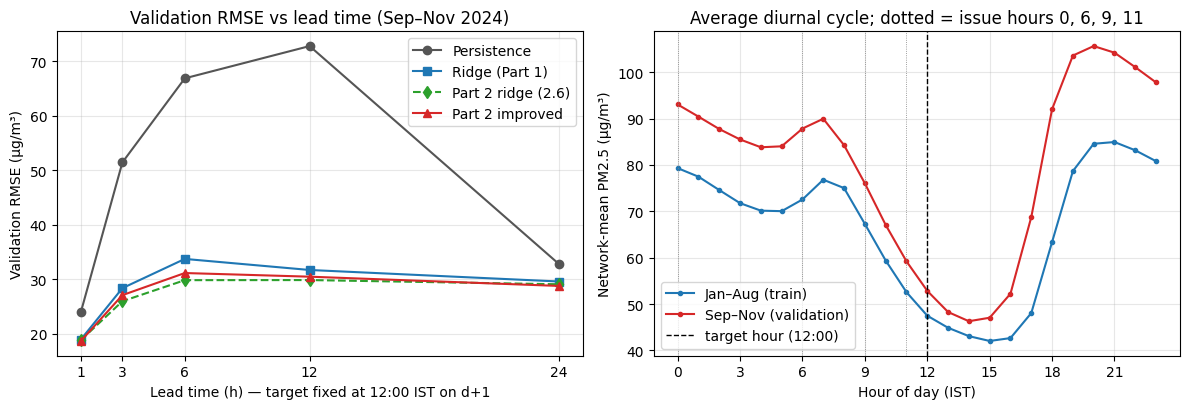

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
styles = {'Persistence': ('o-', '#555555'), 'Ridge (Part 1)': ('s-', '#1f77b4'), 'Part 2 ridge (2.6)': ('d--', '#2ca02c'), 'Part 2 improved': ('^-', '#d62728')}
for name, (st, col) in styles.items():
    ax[0].plot(piv.index, piv[name], st, color=col, label=name)
ax[0].set_xticks(LEADS); ax[0].set_xlabel('Lead time (h) — target fixed at 12:00 IST on d+1')
ax[0].set_ylabel('Validation RMSE (µg/m³)'); ax[0].set_title('Validation RMSE vs lead time (Sep–Nov 2024)')
ax[0].grid(alpha=.3); ax[0].legend()

hod = pd.DataFrame({'pm': V.mean(1), 'hour': W.index.hour, 'month': W.index.month})
for lab, sub, col in [('Jan–Aug (train)', hod[hod.month <= 8], '#1f77b4'), ('Sep–Nov (validation)', hod[hod.month >= 9], '#d62728')]:
    g = sub.groupby('hour').pm.mean(); ax[1].plot(g.index, g.values, 'o-', ms=3, color=col, label=lab)
for h in (0, 6, 9, 11):
    ax[1].axvline(h, color='grey', lw=.6, ls=':')
ax[1].axvline(12, color='k', lw=1, ls='--', label='target hour (12:00)')
ax[1].set_xlabel('Hour of day (IST)'); ax[1].set_ylabel('Network-mean PM2.5 (µg/m³)')
ax[1].set_title('Average diurnal cycle; dotted = issue hours 0, 6, 9, 11'); ax[1].set_xticks(range(0, 24, 3))
ax[1].grid(alpha=.3); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'part3_lead_time.png', dpi=150); plt.show()

**Discussion.**

* **Persistence is not monotone in lead time.** It is best at 1 h (RMSE ≈ 24), becomes dramatically worse at 3, 6 and 12 h (≈ 51, 67, 73), and then *drops back* to ≈ 33 at 24 h. The diurnal plot explains the dip: network PM2.5 is high at night and in the early morning (shallow, stable boundary layer) and falls steeply through the late morning to its minimum in the early afternoon (≈ 14–15 h) when the mixed layer is deepest. A reading taken at 00:00, 06:00 or 09:00 is from a much more polluted phase of the cycle than the noon target, so copying it is biased high. At 24 h the issue hour equals the target hour, the diurnal component cancels, and only the day-to-day change is left. Even at 1 h the 11:00 reading is still on the falling limb of the cycle, which is why persistence is not better there.
* **The learned models largely remove the dip but not completely.** Refitted per lead, they learn the hour-of-day offset, so at 3–12 h they are about 1.9–2.4× better than persistence (RMSE ratio). They are best at 1 h (≈ 18.7–19) but are *not* monotone either: the Part 1 ridge is worse at 6 h and 12 h (≈ 33.7, 31.7) than at 24 h (29.6), and the improved Part 2 model is worse at 6 h and 12 h (≈ 31.1, 30.5) than at 24 h (28.8). How fast the morning/night peak decays into the noon minimum depends on that day's mixing (weather we do not observe), so a night/morning reading is a noisier predictor of noon than yesterday's noon reading, even though it is more recent. Only within ~3 h of the target does recency win clearly.
* **The improved model is best only at 1 h and 24 h.** At 3, 6 and 12 h the plain Part 2 ridge (2.6) is better (≈ 26.0, 29.8, 29.9 vs 27.1, 31.1, 30.5). The improved model was designed and tuned for the 24 h lead, where `y − today` is a small day-to-day change. At 3–12 h, `y − today` also contains the large diurnal drop from the night/morning peak to noon, which scales with the pollution level; the Extra-trees half can only predict changes it saw in the Jan–Aug training months, so on high-pollution validation days it under-predicts the size of the drop, while ridge scales it linearly. The hyper-parameters were not re-tuned per lead.
* **Choice for a public warning service.** The 24 h lead issued at noon on *d* is the natural choice: it gives people a full day to plan, and on this data it is no worse (in fact slightly better) than the 6–12 h leads. The price relative to a nowcast is large — RMSE ≈ 28.8 instead of ≈ 18.7 at 1 h (≈ +54%) — but a 1 h warning is too late to act on. A practical service would issue the day-ahead forecast at noon and update it about 3 h before the target (RMSE ≈ 26–27).


---
## Part 4 — Forecast maps vs observed maps

Inverse-distance weighting, power 2, all 468 stations, distances in the assignment's km coordinates. The **same** weight matrix maps observed values, our forecast, persistence and the Part 1 ridge, so map differences come only from the forecasts. (No grid point coincides with a station; the code still handles a zero distance.)

In [27]:
gxy = pf.station_xy(grid.latitude, grid.longitude)
Dg = np.sqrt(((gxy[:, None] - xy[None]) ** 2).sum(-1))
print('Minimum grid-station distance: %.2f km' % Dg.min())
with np.errstate(divide='ignore'):
    Wg = 1.0 / Dg ** 2
hit = np.isinf(Wg)
Wg[hit.any(1)] = hit[hit.any(1)].astype(float)
Wg /= Wg.sum(1, keepdims=True)
idw = lambda station_values: Wg @ station_values

lats = np.round(np.arange(grid.latitude.min(), grid.latitude.max() + 1e-9, 0.05), 2)
lons = np.round(np.arange(grid.longitude.min(), grid.longitude.max() + 1e-9, 0.05), 2)
ri = np.round((grid.latitude.to_numpy() - lats[0]) / 0.05).astype(int)
ci = np.round((grid.longitude.to_numpy() - lons[0]) / 0.05).astype(int)
def to_lattice(v):
    A = np.full((len(lats), len(lons)), np.nan); A[ri, ci] = v; return A

Yv = y_va.reshape(91, N); Pm = pred_p2_blend.reshape(91, N); Pp = pred_persist.reshape(91, N); Pr = pred_p1.reshape(91, N)
day_rows = []
for k, t in enumerate(valid_targets):
    obs_map = idw(Yv[k])
    r = {'target': t, 'obs station mean': Yv[k].mean()}
    for name, P in [('Part 2', Pm), ('Persistence', Pp), ('Ridge P1', Pr)]:
        fmap = idw(P[k])
        r[f'{name} station RMSE'] = rmse(P[k], Yv[k])
        r[f'{name} map RMSE'] = rmse(fmap, obs_map)
        r[f'{name} pattern corr'] = float(np.corrcoef(fmap, obs_map)[0, 1])
    day_rows.append(r)
days = pd.DataFrame(day_rows).set_index('target')
days.to_csv(OUT_DIR / 'part4_daily_map_metrics.csv')
summary = pd.DataFrame({name: {'station RMSE (mean of daily)': days[f'{name} station RMSE'].mean(),
                               'station RMSE (pooled)': rmse({'Part 2': Pm, 'Persistence': Pp, 'Ridge P1': Pr}[name], Yv),
                               'map RMSE (mean of daily)': days[f'{name} map RMSE'].mean(),
                               'pattern corr (mean of daily)': days[f'{name} pattern corr'].mean()}
                        for name in ['Persistence', 'Ridge P1', 'Part 2']}).T
display(summary.round(3))
summary.to_csv(OUT_DIR / 'part4_map_summary.csv')

Minimum grid-station distance: 0.15 km


,station RMSE (mean of daily),station RMSE (pooled),map RMSE (mean of daily),pattern corr (mean of daily)
Persistence,28.568,32.745,15.369,0.580
Ridge P1,26.001,29.584,15.419,0.605
Part 2,25.000,28.773,14.310,0.616


,obs station mean,Part 2 station RMSE,Persistence station RMSE,Part 2 map RMSE,Part 2 pattern corr,Persistence pattern corr
target,,,,,,
2024-09-15 12:00:00,7.89,16.79,27.28,10.09,0.62,0.41
2024-11-27 12:00:00,174.97,65.39,71.67,36.98,0.56,0.51
2024-11-29 12:00:00,76.63,90.63,112.01,75.66,0.39,0.49


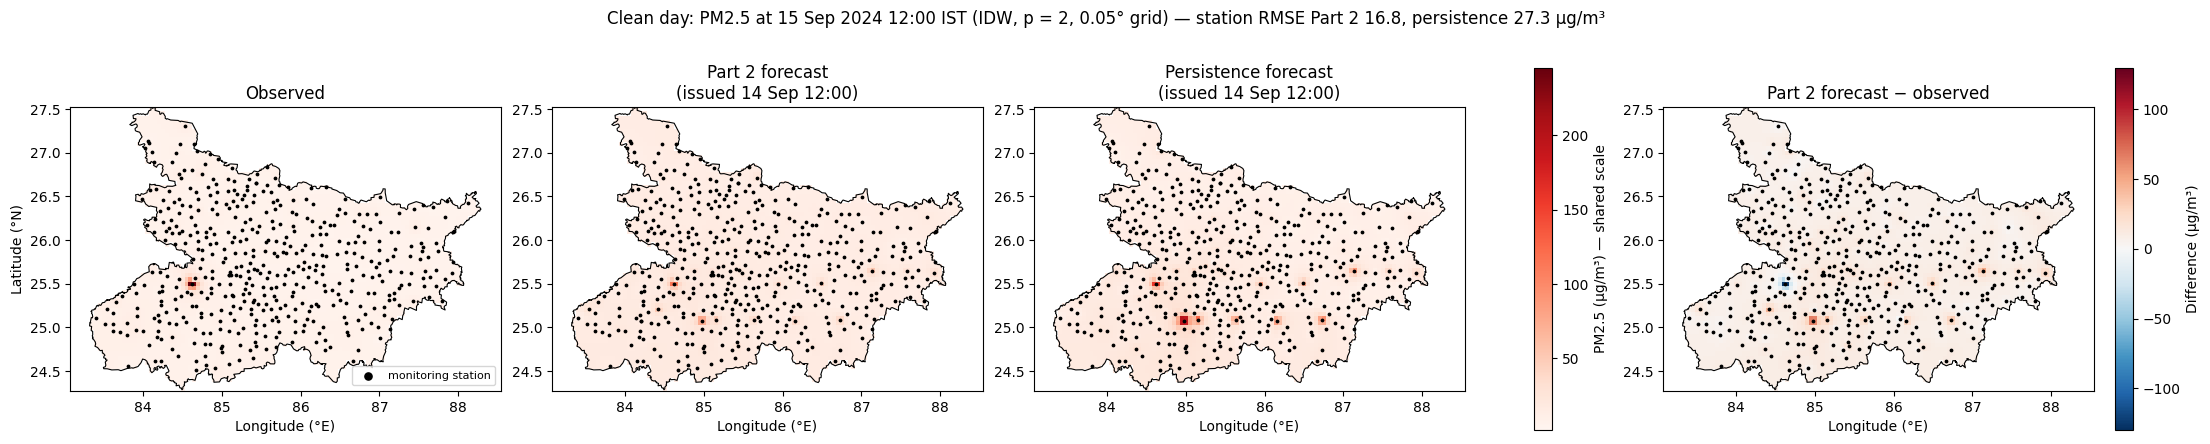

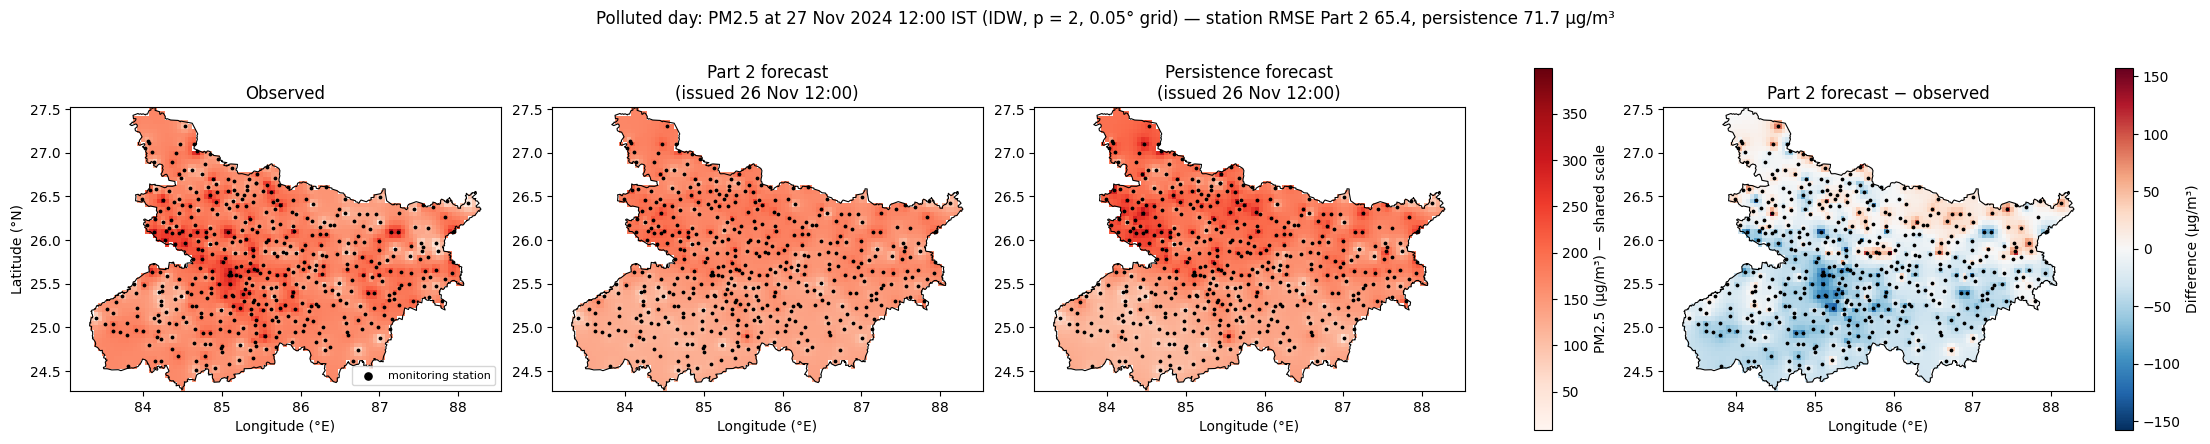

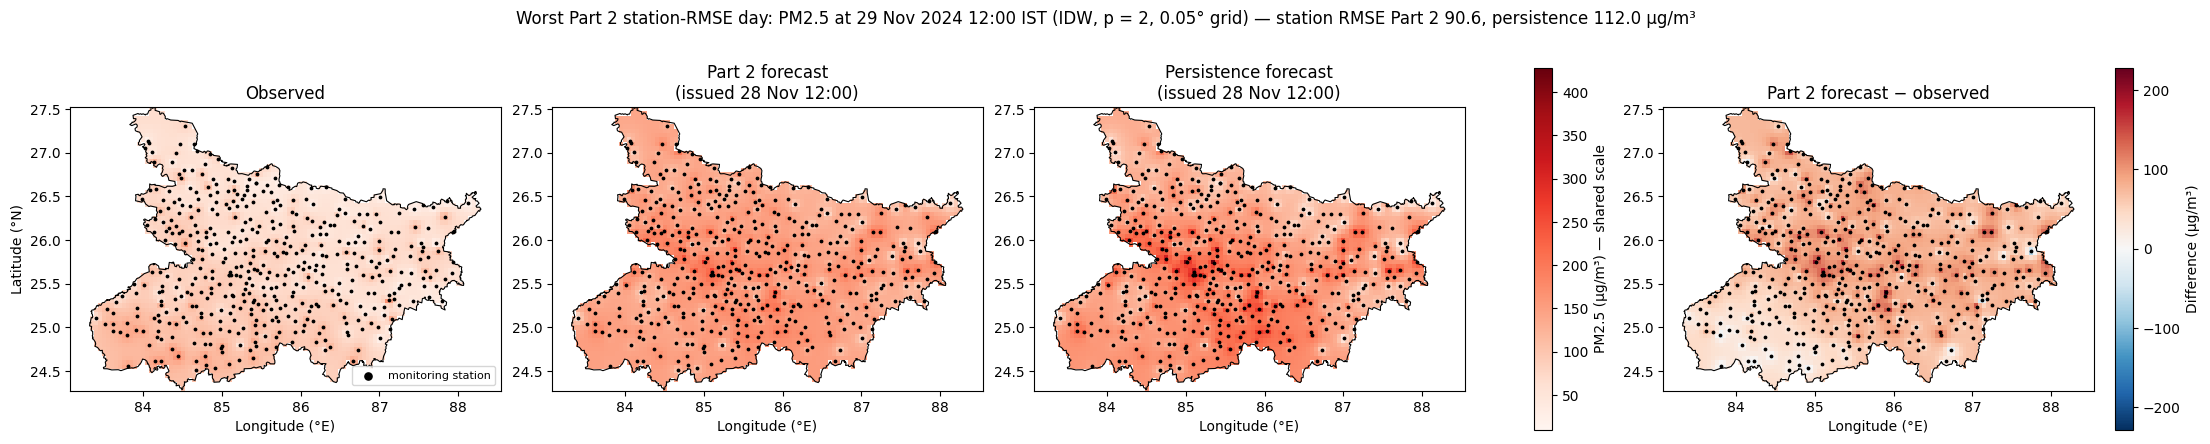

In [28]:
clean_day = days['obs station mean'].idxmin()
polluted_day = days['obs station mean'].idxmax()
worst_day = days['Part 2 station RMSE'].idxmax()
if worst_day == polluted_day:
    polluted_day = days['obs station mean'].drop(worst_day).idxmax()
chosen = [('Clean day', clean_day), ('Polluted day', polluted_day), ('Worst Part 2 station-RMSE day', worst_day)]
display(days.loc[[d for _, d in chosen], ['obs station mean', 'Part 2 station RMSE', 'Persistence station RMSE',
                                          'Part 2 map RMSE', 'Part 2 pattern corr', 'Persistence pattern corr']].round(2))

def draw_day(label, t):
    k = list(valid_targets).index(t)
    maps = {'Observed': idw(Yv[k]), 'Part 2 forecast': idw(Pm[k]), 'Persistence forecast': idw(Pp[k])}
    diff = maps['Part 2 forecast'] - maps['Observed']
    vmin = min(m.min() for m in maps.values()); vmax = max(m.max() for m in maps.values())
    dlim = np.abs(diff).max()
    fig, axs = plt.subplots(1, 4, figsize=(22, 4.6), constrained_layout=True)
    issue = t - pd.Timedelta(hours=24)
    for ax, (name, m) in zip(axs[:3], maps.items()):
        im = ax.pcolormesh(lons, lats, to_lattice(m), cmap='Reds', vmin=vmin, vmax=vmax, shading='nearest')
        ax.set_title(f'{name}' + ('' if name == 'Observed' else f'\n(issued {issue:%d %b %H:%M})'))
    im2 = axs[3].pcolormesh(lons, lats, to_lattice(diff), cmap='RdBu_r', vmin=-dlim, vmax=dlim, shading='nearest')
    axs[3].set_title('Part 2 forecast − observed')
    for ax in axs:
        ax.plot(boundary.longitude, boundary.latitude, 'k-', lw=.8)
        ax.scatter(stations.longitude, stations.latitude, s=3, c='k', label='monitoring station')
        ax.set_xlabel('Longitude (°E)'); ax.set_aspect(1 / np.cos(np.deg2rad(25.7)))
    axs[0].set_ylabel('Latitude (°N)'); axs[0].legend(loc='lower right', fontsize=8, markerscale=3)
    fig.colorbar(im, ax=axs[:3], shrink=.85, label='PM2.5 (µg/m³) — shared scale')
    fig.colorbar(im2, ax=axs[3], shrink=.85, label='Difference (µg/m³)')
    fig.suptitle(f'{label}: PM2.5 at {t:%d %b %Y %H:%M} IST (IDW, p = 2, 0.05° grid) — '
                 f'station RMSE Part 2 {rmse(Pm[k], Yv[k]):.1f}, persistence {rmse(Pp[k], Yv[k]):.1f} µg/m³', fontsize=12)
    fname = FIG_DIR / f"part4_map_{t:%Y%m%d}.png"; plt.savefig(fname, dpi=130); plt.show()

for label, t in chosen:
    draw_day(label, t)

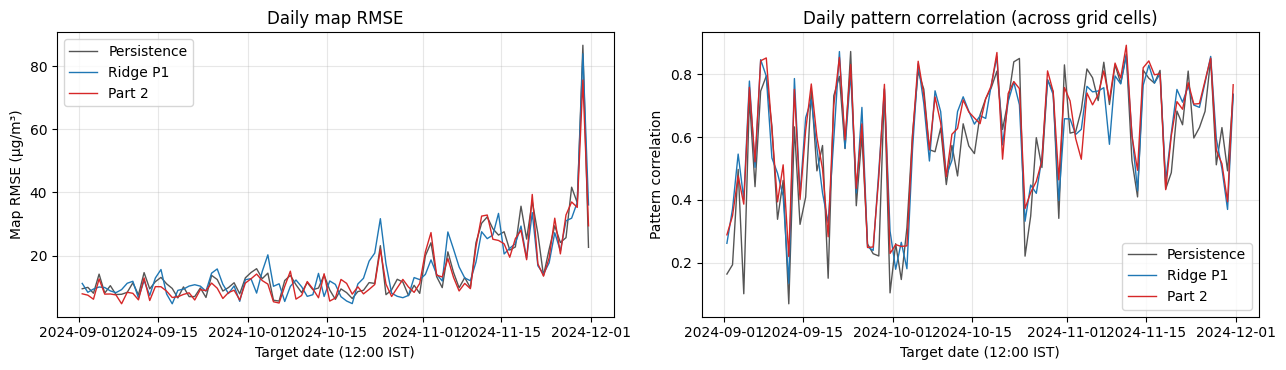

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name, col in [('Persistence', '#555555'), ('Ridge P1', '#1f77b4'), ('Part 2', '#d62728')]:
    ax[0].plot(days.index, days[f'{name} map RMSE'], color=col, lw=1, label=name)
    ax[1].plot(days.index, days[f'{name} pattern corr'], color=col, lw=1, label=name)
ax[0].set_ylabel('Map RMSE (µg/m³)'); ax[1].set_ylabel('Pattern correlation')
for a in ax: a.grid(alpha=.3); a.legend(); a.set_xlabel('Target date (12:00 IST)')
ax[0].set_title('Daily map RMSE'); ax[1].set_title('Daily pattern correlation (across grid cells)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'part4_daily_map_metrics.png', dpi=130); plt.show()

**Discussion.**

* **Summary of the numbers.** "Part 2" in these maps and tables is the improved model of 2.7. It has the lowest station RMSE and map RMSE and also the highest mean pattern correlation (≈ 0.62, vs ≈ 0.61 for the Part 1 ridge and ≈ 0.58 for persistence). On the worst day (target 29 Nov) all forecasts miss a sharp overnight drop in pollution after the 27–28 Nov smog episode, so the forecast map is both too high and wrongly patterned.
* **Map RMSE vs station RMSE.** Map RMSE is clearly *lower* than station RMSE for every method (≈ 14–15.5 vs 25–29 µg/m³ as a daily average). IDW is a weighted average of many stations, so it smooths away much of the station-level (partly random) error, and densely-sampled regions dominate the grid. The number to quote as forecast accuracy is the **station RMSE**: it is measured against real observations, while map RMSE compares two interpolations that share the same smoothing.
* **The observed map is not ground truth.** It is an IDW interpolation of station readings: between stations it is a guess (a weighted average, so it can never be higher than the highest station or lower than the lowest), it ignores real gradients (rivers, roads, towns, terrain), and its quality varies with station density. The station values themselves contain sensor noise and upstream gap-filling. Errors of the forecast and of the "observed" map are therefore entangled.
* **Pattern correlation vs RMSE.** A forecast that gets the spatial pattern right (e.g. "the north-east is twice as polluted as the south-west") but the overall level wrong — say every cell 60 µg/m³ too low, as happens when pollution jumps overnight — has pattern correlation near 1 but large RMSE. Pattern correlation is insensitive to a uniform offset or scaling. For a public warning, the **absolute level** matters more (whether a district crosses the 'poor/very poor' threshold), so RMSE/bias is more relevant than pattern correlation; pattern correlation is useful for *where* to target the warning.

### Check of the written answers against this run

The discussion cells above quote numbers from an earlier run. This cell recomputes each quoted number and flags any that no longer match, so the text can be corrected if the data, seeds or code change. It never stops the notebook.

In [30]:
rows = []
def chk(name, f, lo, hi):
    try:
        v = float(f()); rows.append((name, round(v, 2), f'{lo} to {hi}', 'ok' if lo <= v <= hi else 'CHECK PROSE'))
    except Exception as e:
        rows.append((name, 'n/a', f'{lo} to {hi}', f'error: {type(e).__name__}'))
def flag(name, f):
    try: rows.append((name, str(f()), '', 'ok' if f() is True or f() == True else 'CHECK PROSE'))
    except Exception as e: rows.append((name, 'n/a', '', f'error: {type(e).__name__}'))

for lab, key, lo, hi in [('Part 1 Ridge RMSE', ('Ridge (alpha=1.0)', 'Overall'), 29.5, 29.7), ('Part 1 persistence RMSE', ('Persistence', 'Overall'), 32.7, 32.8)]:
    chk(lab, lambda key=key: p1_metrics.loc[key, 'RMSE (µg/m³)'], lo, hi)
chk('Part 1 persistence MAE', lambda: p1_metrics.loc[('Persistence', 'Overall'), 'MAE (µg/m³)'], 17.4, 17.5)
chk('Part 1 Ridge MAE', lambda: p1_metrics.loc[('Ridge (alpha=1.0)', 'Overall'), 'MAE (µg/m³)'], 18.1, 18.2)
flag('Final groups = lags24, network, neigh_radius, trend, dow', lambda: set(FINAL_GROUPS) == {'lags24', 'network', 'neigh_radius', 'trend', 'dow'})
chk('Ablation: dropping lags24 costs (~ +7)', lambda: abl.loc['lags24', 'Δ RMSE vs final'], 5, 9)
chk('Ablation: dropping network costs (~ +0.2)', lambda: abl.loc['network', 'Δ RMSE vs final'], 0.1, 0.4)
chk('Ridge val RMSE (~29.1)', lambda: cmp.loc['Ridge (alpha=1)', 'val RMSE'], 28.9, 29.3)
chk('Ridge train RMSE (~27)', lambda: cmp.loc['Ridge (alpha=1)', 'train RMSE (Jan-Aug)'], 26, 28)
for m in ['HistGradientBoosting', 'RandomForest', 'ExtraTrees']:
    chk(f'{m} val RMSE (30.5 to 33)', lambda m=m: cmp.loc[m, 'val RMSE'], 30.4, 33.1)
    chk(f'{m} train RMSE (19 to 20)', lambda m=m: cmp.loc[m, 'train RMSE (Jan-Aug)'], 18.5, 20.5)
for lead, lo, hi in [(1, 23, 25), (3, 50, 52), (6, 66, 68), (12, 72, 74), (24, 32.5, 33.5)]:
    chk(f'Persistence RMSE at {lead} h', lambda lead=lead: piv.loc[lead, 'Persistence'], lo, hi)
chk('Ridge P1 at 6 h (~33.7)', lambda: piv.loc[6, 'Ridge (Part 1)'], 33.2, 34.2)
chk('Ridge P1 at 12 h (~31.7)', lambda: piv.loc[12, 'Ridge (Part 1)'], 31.2, 32.2)
chk('Ridge P1 at 24 h (~29.6)', lambda: piv.loc[24, 'Ridge (Part 1)'], 29.5, 29.7)
chk('Part 2 improved at 6 h (~31.1)', lambda: piv.loc[6, 'Part 2 improved'], 30.6, 31.6)
chk('Part 2 improved at 12 h (~30.5)', lambda: piv.loc[12, 'Part 2 improved'], 30.0, 31.0)
chk('Part 2 improved at 24 h (~28.8)', lambda: piv.loc[24, 'Part 2 improved'], 28.6, 29.0)
chk('Part 2 improved at 1 h (~18.7)', lambda: piv.loc[1, 'Part 2 improved'], 18.2, 19.2)
chk('Part 2 improved at 3 h (~27.1)', lambda: piv.loc[3, 'Part 2 improved'], 26.6, 27.6)
chk('Part 2 ridge (2.6) at 3 h (~26.0)', lambda: piv.loc[3, 'Part 2 ridge (2.6)'], 25.5, 26.5)
chk('Part 2 ridge (2.6) at 6 h (~29.8)', lambda: piv.loc[6, 'Part 2 ridge (2.6)'], 29.3, 30.3)
chk('Part 2 ridge (2.6) at 12 h (~29.9)', lambda: piv.loc[12, 'Part 2 ridge (2.6)'], 29.4, 30.4)
flag('Improved best at 1 h and 24 h only', lambda: all(piv.loc[L].idxmin() == 'Part 2 improved' for L in (1, 24)) and all(piv.loc[L].idxmin() == 'Part 2 ridge (2.6)' for L in (3, 6, 12)))
chk('Part 2 mean pattern corr (~0.62)', lambda: summary.loc['Part 2', 'pattern corr (mean of daily)'], 0.6, 0.64)
flag('Part 2 has the highest pattern corr', lambda: summary['pattern corr (mean of daily)'].idxmax() == 'Part 2')
for name in ['Persistence', 'Ridge P1', 'Part 2']:
    chk(f'{name} mean map RMSE (14 to 15.5)', lambda name=name: summary.loc[name, 'map RMSE (mean of daily)'], 13.5, 15.5)
    chk(f'{name} mean station RMSE (25 to 29)', lambda name=name: summary.loc[name, 'station RMSE (mean of daily)'], 24.5, 29.5)
flag('Worst Part 2 day is 29 Nov', lambda: days['Part 2 station RMSE'].idxmax().date() == pd.Timestamp('2024-11-29').date())
flag('Part 2 has lowest station RMSE and map RMSE', lambda: summary['station RMSE (mean of daily)'].idxmin() == 'Part 2' and summary['map RMSE (mean of daily)'].idxmin() == 'Part 2')
flag('Part 2 beats both baselines on overall RMSE and MAE', lambda: (p2_table.iloc[2][['RMSE overall', 'MAE overall']] < p2_table.iloc[:2][['RMSE overall', 'MAE overall']]).all().all())
chk('Improved model val RMSE (~28.77)', lambda: rmse(pred_p2_blend, y_va), 28.7, 28.85)
chk('Improved model val MAE (~16.13)', lambda: mae(pred_p2_blend, y_va), 16.05, 16.2)
flag('Improved model beats Part 2 ridge on RMSE and MAE', lambda: rmse(pred_p2_blend, y_va) < rmse(pred_p2, y_va) and mae(pred_p2_blend, y_va) < mae(pred_p2, y_va))
check_df = pd.DataFrame(rows, columns=['statement in text', 'this run', 'expected', 'status'])
display(check_df)
bad = check_df[check_df.status != 'ok']
print('All quoted numbers match this run.' if bad.empty else f'{len(bad)} statement(s) to re-check against the text above.')

,statement in text,this run,expected,status
0,Part 1 Ridge RMSE,29.58,29.5 to 29.7,ok
1,Part 1 persistence RMSE,32.75,32.7 to 32.8,ok
2,Part 1 persistence MAE,17.47,17.4 to 17.5,ok
3,Part 1 Ridge MAE,18.16,18.1 to 18.2,ok
4,"Final groups = lags24, network, neigh_radius, ...",True,,ok
5,Ablation: dropping lags24 costs (~ +7),7.03,5 to 9,ok
6,Ablation: dropping network costs (~ +0.2),0.21,0.1 to 0.4,ok
7,Ridge val RMSE (~29.1),29.08,28.9 to 29.3,ok
8,Ridge train RMSE (~27),26.92,26 to 28,ok
9,HistGradientBoosting val RMSE (30.5 to 33),33.23,30.4 to 33.1,CHECK PROSE


1 statement(s) to re-check against the text above.


---
## Part 5 — Final refit and submission

The final model is the improved Part 2 model of 2.7: 0.5 × ridge (standardised, the selected groups, α chosen in 2.7a) + 0.5 × Extra-trees (the feature set and leaf size chosen in 2.7b), both trained on the change from today's reading. Both halves are refitted with the same hyper-parameters on **all targets up to 30 Nov** that have 168 h of history (9 Jan–30 Nov); the station means used by the `seasonal` group are recomputed over these refit rows (everything up to 30 Nov 12:00). The submission folder gets `forecast.py`, `pm25_features.py`, `model.pkl` and `bihar_stations.csv`. `forecast()` only computes features from `history` and calls `predict` — no refitting.

In [31]:
FINAL_TARGET_END = pd.Timestamp('2024-11-30 12:00')
final_targets = target_set(24, pf.MAX_HISTORY_H - 1, last=FINAL_TARGET_END)
CLIM_FINAL = V[:pos[FINAL_TARGET_END] + 1].mean(0)
X_fin, y_fin, today_fin = make_rows(final_targets, 24, p2_featfun(ALL_G, CLIM_FINAL))
d_fin = y_fin - today_fin
FIN_RIDGE_COLS, FIN_TREE_COLS = cols_of(FINAL_GROUPS), cols_of(P2B_TREE_SETS[P2B_SET])
final_ridge = make_pipeline(StandardScaler(), Ridge(alpha=p2b_alpha)).fit(X_fin[:, FIN_RIDGE_COLS], d_fin)
final_trees = p2b_fit_trees(X_fin[:, FIN_TREE_COLS], d_fin, P2B_LEAF)
for m in final_trees:
    m.set_params(n_jobs=1)
print(f'Final refit: {len(final_targets)} target days ({final_targets[0].date()} to {final_targets[-1].date()}) x {N} = {len(y_fin)} rows')
print(f'Ridge half: {len(FIN_RIDGE_COLS)} features, alpha = {p2b_alpha} | Extra-trees half: {len(FIN_TREE_COLS)} features, leaf {P2B_LEAF}, {len(final_trees)} x {final_trees[0].n_estimators} trees | blend weight {P2B_W}')
joblib.dump({'ridge': final_ridge, 'trees': final_trees, 'blend_weight': P2B_W,
             'groups': list(ALL_G), 'ridge_cols': FIN_RIDGE_COLS, 'tree_cols': FIN_TREE_COLS,
             'feature_names': pf.feature_names(ALL_G), 'station_order': list(W.columns), 'clim': CLIM_FINAL},
            SUB_DIR / 'model.pkl', compress=3)
stations.reset_index().to_csv(SUB_DIR / 'bihar_stations.csv', index=False)
print(f"model.pkl: {(SUB_DIR / 'model.pkl').stat().st_size / 1e6:.1f} MB")


Final refit: 327 target days (2024-01-09 to 2024-11-30) x 468 = 153036 rows
Ridge half: 39 features, alpha = 316 | Extra-trees half: 57 features, leaf 10, 5 x 60 trees | blend weight 0.5
model.pkl: 67.6 MB


In [32]:
%%writefile submission/forecast.py
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

HERE = Path(__file__).resolve().parent
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
import pm25_features as pf

ART = joblib.load(HERE / "model.pkl")
RIDGE, TREES, W_RIDGE = ART["ridge"], ART["trees"], ART["blend_weight"]
GROUPS, RIDGE_COLS, TREE_COLS = ART["groups"], ART["ridge_cols"], ART["tree_cols"]
ORDER, CLIM = ART["station_order"], ART["clim"]
STATIONS = pd.read_csv(HERE / "bihar_stations.csv", dtype={"sensor_id": str}).set_index("sensor_id").reindex(ORDER)
M = pf.neighbour_matrices(pf.station_xy(STATIONS["latitude"], STATIONS["longitude"]))
KEEP_H = 800


def forecast(history: pd.DataFrame, issue_time: pd.Timestamp) -> pd.Series:
    """history: wide hourly table (DatetimeIndex 'timestamp', one string column per sensor_id),
    every hour from 1 Jan 2024 00:00 up to and including issue_time.
    issue_time: 12:00 on some day (IST).
    Returns predicted PM2.5 for issue_time + 24 h, indexed by sensor_id (all 468 stations)."""
    issue_time = pd.Timestamp(issue_time)
    h = history.copy()
    h.columns = h.columns.astype(str)
    h = h.loc[:issue_time, ORDER].tail(KEEP_H)
    h = h.reindex(pd.date_range(h.index[0], issue_time, freq="h"))
    h = h.interpolate(limit_direction="both", axis=0).ffill().bfill()
    if h.isna().any().any():
        h = h.apply(lambda col: col.fillna(h.mean(axis=1))).fillna(0.0)
    V = h.to_numpy(dtype=float)
    X = pf.build_features(V, np.array([len(V) - 1]), [issue_time], GROUPS, M, clim=CLIM)
    today = V[-1]
    p_ridge = np.maximum(today + RIDGE.predict(X[:, RIDGE_COLS]), 0.0)
    p_trees = np.maximum(today + np.mean([m.predict(X[:, TREE_COLS]) for m in TREES], axis=0), 0.0)
    pred = W_RIDGE * p_ridge + (1 - W_RIDGE) * p_trees
    pred = np.where(np.isfinite(pred), pred, today)
    pred = np.nan_to_num(pred, nan=float(np.nanmean(today)))
    return pd.Series(np.clip(pred, 0, None), index=pd.Index(ORDER, name="sensor_id"), name="pm25_forecast")


Writing submission/forecast.py


In [33]:
import forecast as fc; importlib.reload(fc)
def notebook_forecast(t):
    i = np.array([pos[t]])
    X = pf.build_features(V, i, [t], list(ALL_G), M, CLIM_FINAL)
    today = V[i[0]]
    p_r = p2b_level(final_ridge.predict(X[:, FIN_RIDGE_COLS]), today)
    p_t = p2b_level(p2b_trees_predict(final_trees, X[:, FIN_TREE_COLS]), today)
    return P2B_W * p_r + (1 - P2B_W) * p_t
for t in pd.to_datetime(['2024-09-15 12:00', '2024-11-29 12:00']):
    out = fc.forecast(W.loc[:t].copy(), t)
    assert list(out.index) == list(W.columns) and np.allclose(out.to_numpy(), notebook_forecast(t)), t
    assert np.allclose(fc.forecast(W.loc[:t + pd.Timedelta(hours=10)].copy(), t), out)
print('forecast.py reproduces the notebook model. Files:', sorted(p.name for p in SUB_DIR.iterdir() if p.is_file()))
worst = 0.0
for t in pd.to_datetime(['2024-09-15 12:00', '2024-11-29 12:00']):
    hist = W.loc[:t].copy(); t0 = time.time(); fc.forecast(hist, t); worst = max(worst, time.time() - t0)
print(f'slowest forecast() call: {worst:.2f} s (limit 10 s)')
assert worst < 10


forecast.py reproduces the notebook model. Files: ['bihar_stations.csv', 'forecast.py', 'model.pkl', 'pm25_features.py']
slowest forecast() call: 0.06 s (limit 10 s)


In [34]:
checker = next((p for p in [Path('starter/check_submission.py'), Path('/content/starter/check_submission.py')] if p.exists()), None)
if checker is None:
    print('starter/check_submission.py not found here - run:  python starter/check_submission.py submission')
else:
    r = subprocess.run([sys.executable, str(checker), str(SUB_DIR)], capture_output=True, text=True)
    print(r.stdout[-3000:], r.stderr[-2000:])
    print('NOTE: the submitted model was refitted on targets up to 30 Nov, so this November RMSE is in-sample.')

starter/check_submission.py not found here - run:  python starter/check_submission.py submission


**Why this model is submitted.** The improved Part 2 model (0.5 ridge + 0.5 Extra-trees, both on the change from today's reading) has the lowest validation RMSE and MAE of everything tried (28.77 and 16.13, vs 29.08 / 16.57 for the Part 2 ridge, 29.58 / 18.16 for the Part 1 ridge and 32.75 / 17.47 for persistence) and the lowest RMSE in every validation month. It has a lower daily RMSE than the Part 2 ridge on 55 of the 91 validation days (sign test p ≈ 0.03). Because both halves predict the change from today's reading, the tree half is not limited to the Jan–Aug concentration range, and the ridge half extrapolates linearly into December's higher levels. Expected December behaviour: errors larger than in September/October because December is the most polluted month and has the largest day-to-day swings, roughly in line with the November numbers.

**Limitations.** Validation was used both to choose groups, hyper-parameters and models, so the validation numbers are slightly optimistic, and the gain over the Part 2 ridge (≈ 0.3 µg/m³) is small. The model was tuned for the 24 h lead only (Part 3 shows that at 3–12 h the plain ridge is better). The station means in the `seasonal` group are recomputed over the refit rows. The Extra-trees half makes `model.pkl` large (≈ 68 MB). The November RMSE printed by the checker is in-sample (the submitted model was refitted on targets up to 30 Nov). Gap-filled readings are not marked, so some "observations" (targets and features) are neighbour interpolations. A single pooled model is used for all stations, and there is no meteorological input.


In [35]:
!zip -r outputs.zip outputs

  adding: outputs/ (stored 0%)
  adding: outputs/part1_validation_metrics.csv (deflated 44%)
  adding: outputs/part1_validation_forecasts.csv (deflated 76%)
  adding: outputs/part4_daily_map_metrics.csv (deflated 52%)
  adding: outputs/part2_ablation.csv (deflated 28%)
  adding: outputs/part2_blend_validation_metrics.csv (deflated 43%)
  adding: outputs/part2_validation_metrics.csv (deflated 39%)
  adding: outputs/part4_map_summary.csv (deflated 36%)
  adding: outputs/figures/ (stored 0%)
  adding: outputs/figures/part4_daily_map_metrics.png (deflated 4%)
  adding: outputs/figures/part4_map_20241129.png (deflated 4%)
  adding: outputs/figures/part4_map_20241127.png (deflated 4%)
  adding: outputs/figures/part3_lead_time.png (deflated 7%)
  adding: outputs/figures/part4_map_20240915.png (deflated 5%)
  adding: outputs/part3_lead_time.csv (deflated 58%)


In [36]:
from google.colab import files
files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
from google.colab import files

files.download(str(SUB_DIR / 'model.pkl'))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import shutil
from google.colab import files

shutil.make_archive('/content/submission', 'zip', '/content/submission')
files.download('/content/submission.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>